# The Hedgehogs of Wall Street
## From Financial Fundamentals to Credit Risk: An Explainable Machine Learning Screener

**Cours** : Analyse de données et Apprentissage Automatique — IMT Atlantique
**Équipe** : Baptiste Gauthier, Sami Guessoum
**Dépôt GitHub** : https://github.com/samiguessoum/hedgehogs-credit-risk-ml

---

**Sommaire (partie 1 : exploration des données)**
0. Description du projet et du dataset
1. Imports
2. Accès aux données
3. Métadonnées
4. Valeurs manquantes, doublons et structure des entreprises
5. Étude de la cible
6. Distributions, valeurs extrêmes et mise à l'échelle
7. Corrélations, variables catégorielles et sélection
8. Réduction de dimension et détection d'anomalies
9. Clustering non supervisé
10. Conclusions de l'exploration et décisions pour la modélisation

*Les parties « Modèles de base et d'ensemble » puis « Modèles améliorés et tuning » seront ajoutées à la suite de ce notebook.*

# 0. Description du projet et du dataset

## Objectif

Notre projet vise à prédire la qualité de crédit d'une entreprise à partir de ses fondamentaux financiers, afin d'aider un investisseur à évaluer rapidement son niveau de risque.

Le problème est traité principalement comme une **classification binaire** : distinguer les entreprises **Investment Grade** (note BBB- ou mieux) des entreprises **Speculative Grade** (BB+ ou moins). En extension, nous testerons une **classification multiclasse** en regroupant les notes détaillées en niveaux de risque.

Démarche : analyse exploratoire, prétraitement, *feature engineering* et sélection de variables, puis comparaison de plusieurs modèles, des modèles linéaires régularisés aux méthodes d'ensemble. Nous étudierons aussi le déséquilibre de classes, l'optimisation des hyperparamètres et l'explicabilité des prédictions.

Une attention particulière est portée au **data leakage** : une même entreprise apparaissant plusieurs fois dans le dataset, les découpages entraînement / test se font **au niveau de l'entreprise**.

## Dataset

- **Source** : [Corporate Credit Rating with Financial Ratios (Kaggle)](https://www.kaggle.com/datasets/kirtandelwadia/corporate-credit-rating-with-financial-ratios)
- **Contenu** : 7 805 notations de crédit émises entre 2010 et 2016 par 7 agences, portant sur **686 entreprises distinctes** (identifiant SEC « CIK »). Le fichier contient 1 377 noms d'entreprise, mais beaucoup sont des variantes d'écriture d'une même société (voir section 4.2).
- **Variables** : 16 ratios financiers (rentabilité, liquidité, endettement, cash-flows, efficacité opérationnelle), des variables catégorielles (secteur, agence de notation, code industriel SIC), la note détaillée et une cible binaire déjà calculée.

## Travaux existants

- **Understanding and Attaining an Investment Grade Rating in the Age of Explainable AI** ([doi:10.1007/s10614-024-10700-7](https://doi.org/10.1007/s10614-024-10700-7)) — le travail le plus proche de notre dataset : ratios financiers et arbres de décision pour extraire des règles explicables menant à une note Investment Grade.
- **Opening a New Era with Machine Learning in Financial Services? Forecasting Corporate Credit Ratings Based on Annual Financial Statements** ([MDPI, IJFS 11(3):96](https://www.mdpi.com/2227-7072/11/3/96)) — comparaison de plusieurs méthodes de machine learning pour prédire les notes à partir des états financiers, avec une étude du déséquilibre de classes et des questions de déploiement.
- **CCRD Dataset** ([GitHub](https://github.com/Mengmeara/CCRD-Dataset)) — extension récente qui combine données financières et informations extraites des rapports annuels pour une classification multiclasse des notes.

Notre objectif n'est pas de reproduire ces travaux mais de nous en inspirer pour construire et comparer plusieurs pipelines, avec une attention particulière au *data leakage*, à la validation au niveau de l'entreprise et à l'explicabilité. L'orientation retenue est celle d'un **outil de screening du risque** pour l'aide à la décision d'investissement.

# 1. Imports

Toutes les bibliothèques du projet sont importées ici. Elles sont **toutes préinstallées sur Google Colab** : aucune installation supplémentaire n'est nécessaire.
Versions utilisées lors de l'exécution : voir la sortie de la cellule.

In [1]:
# --- Manipulation de données
import numpy as np                      # testé avec numpy >= 1.26
import pandas as pd                     # testé avec pandas >= 2.2
from itertools import combinations

# --- Visualisation
import matplotlib                       # testé avec matplotlib >= 3.8
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns                   # testé avec seaborn >= 0.13

# --- Statistiques
import scipy                            # testé avec scipy >= 1.11
from scipy import stats

# --- Machine learning (scikit-learn >= 1.4)
import sklearn
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# --- Reproductibilité
SEED = 42
np.random.seed(SEED)

# --- Style graphique commun à tout le notebook
# Deux couleurs fixes, distinguables par les daltoniens :
# bleu = Investment Grade, orange = Speculative Grade.
C_IG, C_SG, C_NEUTRE = "#2a78d6", "#eb6834", "#898781"
PAL_CIBLE = {"IG": C_IG, "SG": C_SG}
# Échelle divergente (corrélations, profils) : violet = négatif, vert d'eau = positif.
# Volontairement différente du bleu/orange, réservés à la cible.
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#6250d6", "#f0efec", "#1baf7a"])
CMAP_SEQ = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#86b6ef", "#1c5cab"])
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False,
                     "grid.color": "#e1e0d9", "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__,
      "| seaborn", sns.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2 | seaborn 0.13.2 | scipy 1.18.1 | scikit-learn 1.9.1


# 2. Accès aux données

Le dataset est hébergé dans le dépôt GitHub du projet. L'URL ci-dessous pointe vers une **version figée** du fichier (identifiant de commit), pour que les résultats restent reproductibles même si le dépôt évolue.

- Dépôt : https://github.com/samiguessoum/hedgehogs-credit-risk-ml
- Source originale : https://www.kaggle.com/datasets/kirtandelwadia/corporate-credit-rating-with-financial-ratios

Si GitHub n'est pas joignable, le code se rabat sur une copie locale du fichier (par exemple après un `git clone`).

In [2]:
DATA_URL = ("https://raw.githubusercontent.com/samiguessoum/hedgehogs-credit-risk-ml/"
            "ecb08714ce1490bb43507de3720f7558871c3c8b/corporateCreditRatingWithFinancialRatios.csv")
LOCAL_PATH = "corporateCreditRatingWithFinancialRatios.csv"

try:
    df_raw = pd.read_csv(DATA_URL)
except Exception:
    df_raw = pd.read_csv(LOCAL_PATH)

df = df_raw.copy()
print(f"{df.shape[0]} lignes x {df.shape[1]} colonnes")
df.head()

7805 lignes x 25 colonnes


,Rating Agency,Corporation,Rating,Rating Date,CIK,Binary Rating,SIC Code,Sector,Ticker,Current Ratio,Long-term Debt / Capital,Debt/Equity Ratio,Gross Margin,Operating Margin,EBIT Margin,EBITDA Margin,Pre-Tax Profit Margin,Net Profit Margin,Asset Turnover,ROE - Return On Equity,Return On Tangible Equity,ROA - Return On Assets,ROI - Return On Investment,Operating Cash Flow Per Share,Free Cash Flow Per Share
0,Standard & Poor's Ratings Services,American States Water Co.,A-,2010-07-30,1056903,1,4941.0,Utils,AWR,1.1507,0.4551,0.8847,77.6230,19.4839,19.4839,28.9834,13.6093,8.3224,0.3173,8.1724,8.1978,2.6385,4.4530,1.9957,-0.1333
1,Standard & Poor's Ratings Services,Automatic Data Processing Inc.,AAA,2010-09-16,8670,1,7374.0,BusEq,ADP,1.1129,0.0072,0.0073,43.6619,19.8327,19.8327,23.9379,20.8699,13.5690,0.3324,22.0354,47.2858,4.4944,21.8765,0.2501,0.3132
2,Standard & Poor's Ratings Services,Avnet Inc.,BBB-,2010-11-23,8858,1,5065.0,Shops,AVT,1.9276,0.2924,0.4255,11.9008,3.3173,3.3173,3.6338,3.0536,2.1418,2.4620,13.6376,16.7991,5.2731,9.6494,-7.6079,-7.3231
3,Standard & Poor's Ratings Services,California Water Service Co.,AA-,2010-06-29,1035201,1,4941.0,Utils,CWT,0.8358,0.4708,0.9491,64.5096,18.4549,18.4549,27.9377,15.1135,9.0246,0.2946,9.6412,9.7015,2.6583,5.1018,1.7438,-0.8999
4,Standard & Poor's Ratings Services,Cardinal Health Inc.,A,2010-07-14,721371,1,5122.0,Shops,CAH,1.2931,0.2644,0.4036,3.8385,1.3269,1.3269,1.5847,1.2304,0.6518,4.9276,11.1256,19.4184,2.9364,8.1844,1.9725,2.4174


# 3. Métadonnées

## 3.1 Types et rôle de chaque colonne

In [3]:
RATIOS = ["Current Ratio", "Long-term Debt / Capital", "Debt/Equity Ratio",
          "Gross Margin", "Operating Margin", "EBIT Margin", "EBITDA Margin",
          "Pre-Tax Profit Margin", "Net Profit Margin", "Asset Turnover",
          "ROE - Return On Equity", "Return On Tangible Equity",
          "ROA - Return On Assets", "ROI - Return On Investment",
          "Operating Cash Flow Per Share", "Free Cash Flow Per Share"]

FAMILLE = {"Current Ratio": "Liquidité",
           "Long-term Debt / Capital": "Endettement", "Debt/Equity Ratio": "Endettement",
           "Gross Margin": "Marge", "Operating Margin": "Marge", "EBIT Margin": "Marge",
           "EBITDA Margin": "Marge", "Pre-Tax Profit Margin": "Marge", "Net Profit Margin": "Marge",
           "Asset Turnover": "Efficacité",
           "ROE - Return On Equity": "Rentabilité", "Return On Tangible Equity": "Rentabilité",
           "ROA - Return On Assets": "Rentabilité", "ROI - Return On Investment": "Rentabilité",
           "Operating Cash Flow Per Share": "Cash-flow", "Free Cash Flow Per Share": "Cash-flow"}

ROLE = {"Rating Agency": "Catégorielle (feature candidate)",
        "Corporation": "Identifiant (exclu)", "Rating": "Cible détaillée (multiclasse)",
        "Rating Date": "Date (contexte, exclue comme feature brute)", "CIK": "Identifiant entreprise (groupes de split)",
        "Binary Rating": "Cible binaire (1 = IG, 0 = SG)", "SIC Code": "Catégorielle haute cardinalité",
        "Sector": "Catégorielle (feature candidate)", "Ticker": "Identifiant (exclu)"}

meta = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "nb_valeurs_uniques": df.nunique(),
    "rôle": [ROLE.get(c, f"Numérique : ratio ({FAMILLE.get(c, '')})") for c in df.columns],
})
meta

,type,nb_valeurs_uniques,rôle
Rating Agency,str,7,Catégorielle (feature candidate)
Corporation,str,1377,Identifiant (exclu)
Rating,str,23,Cible détaillée (multiclasse)
Rating Date,str,1414,"Date (contexte, exclue comme feature brute)"
CIK,int64,686,Identifiant entreprise (groupes de split)
Binary Rating,int64,2,"Cible binaire (1 = IG, 0 = SG)"
SIC Code,float64,240,Catégorielle haute cardinalité
Sector,str,12,Catégorielle (feature candidate)
Ticker,str,678,Identifiant (exclu)
Current Ratio,float64,2521,Numérique : ratio (Liquidité)


In [4]:
# Statistiques descriptives des ratios (avec asymétrie et aplatissement)
desc = df[RATIOS].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["skewness"] = df[RATIOS].skew()
desc["kurtosis"] = df[RATIOS].kurt()
desc.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max,skewness,kurtosis
Current Ratio,7805.0,1.93,1.92,0.17,0.48,1.08,1.50,2.16,8.13,34.08,7.26,77.99
Long-term Debt / Capital,7805.0,0.45,2.63,-86.36,0.01,0.29,0.43,0.54,1.61,171.50,21.60,2752.58
Debt/Equity Ratio,7805.0,0.18,34.46,-1473.10,-14.54,0.42,0.75,1.21,26.15,194.38,-27.88,973.78
Gross Margin,7805.0,42.43,23.74,-87.68,4.22,22.45,39.64,59.64,100.00,100.00,0.35,-0.29
Operating Margin,7805.0,11.53,25.47,-461.79,-59.54,6.10,12.12,19.46,47.14,93.99,-9.75,145.31
EBIT Margin,7805.0,11.58,25.48,-461.79,-59.54,6.18,12.16,19.54,47.35,93.99,-9.74,145.04
EBITDA Margin,7805.0,20.07,24.38,-360.82,-38.39,11.16,18.30,30.66,66.43,286.49,-5.90,78.44
Pre-Tax Profit Margin,7805.0,8.66,27.87,-476.01,-75.60,4.01,9.71,16.68,46.06,221.29,-8.66,123.23
Net Profit Margin,7805.0,6.00,24.06,-414.82,-72.87,2.64,6.94,12.37,37.43,219.39,-8.69,129.37
Asset Turnover,7805.0,0.85,0.70,0.07,0.15,0.40,0.66,1.04,3.51,8.50,2.77,12.85


### Interprétation

- **25 colonnes** de quatre natures différentes, qui n'auront pas le même traitement :
  - **16 ratios numériques** : ce sont les vraies variables explicatives ;
  - **3 variables catégorielles** candidates : `Sector` (12 modalités), `Rating Agency` (7) et `SIC Code` (240, haute cardinalité) ;
  - **2 cibles** : `Binary Rating` (binaire) et `Rating` (23 notes détaillées) ;
  - **4 identifiants ou informations de contexte** à exclure des features : `Corporation`, `Ticker`, `CIK` (gardé pour construire les groupes de split) et `Rating Date`.
- Les ratios ont des échelles **très hétérogènes** : un Current Ratio autour de 1,5, des marges exprimées en pourcentage, des cash-flows par action proches de 0. Une mise à l'échelle sera indispensable pour les modèles sensibles aux distances (KNN, SVM, régression logistique).
- Les écarts entre percentiles 1 % et 99 %, et surtout les valeurs min / max, sont **énormes** sur plusieurs ratios : un ROE de −11 258 % ou un Debt/Equity de −1 473. L'asymétrie (*skewness*) et l'aplatissement (*kurtosis*) confirment des **queues de distribution très lourdes** (kurtosis de 2 753 pour LT Debt / Capital). C'est étudié en section 6.

# 4. Valeurs manquantes, doublons et structure des entreprises

## 4.1 Valeurs manquantes et valeurs suspectes

In [5]:
na = df.isna().sum()
print("Valeurs manquantes (NaN) au total :", int(na.sum()))
print("Lignes strictement dupliquées    :", int(df.duplicated().sum()))

# Les NaN peuvent être déguisés : on cherche des valeurs « sentinelles » typiques
suspect = pd.DataFrame({
    "nb_zéros": (df[RATIOS] == 0).sum(),
    "nb_négatifs": (df[RATIOS] < 0).sum(),
    "nb_infinis": np.isinf(df[RATIOS]).sum(),
    "valeur_la_plus_fréquente": df[RATIOS].mode().iloc[0],
    "fréquence_de_cette_valeur": [df[c].value_counts().iloc[0] for c in RATIOS],
})
suspect

Valeurs manquantes (NaN) au total : 0
Lignes strictement dupliquées    : 0


,nb_zéros,nb_négatifs,nb_infinis,valeur_la_plus_fréquente,fréquence_de_cette_valeur
Current Ratio,0,0,0,1.2446,23
Long-term Debt / Capital,0,25,0,0.4496,19
Debt/Equity Ratio,0,299,0,0.3164,17
Gross Margin,0,12,0,100.0000,145
Operating Margin,0,557,0,6.8957,14
EBIT Margin,0,557,0,6.8957,14
EBITDA Margin,0,276,0,6.8957,14
Pre-Tax Profit Margin,0,921,0,6.0485,14
Net Profit Margin,0,990,0,4.0847,14
Asset Turnover,0,0,0,0.3114,18


In [6]:
# Valeurs « non applicables » textuelles et cohérence des codes
print("SIC Code manquants :", df["SIC Code"].isna().sum(), "| Secteurs :", df["Sector"].nunique())
print("Gross Margin = 100 % exactement :", (df["Gross Margin"] == 100).sum(), "lignes")
print("Secteur(s) associé(s) à ces lignes :",
      df.loc[df["Gross Margin"] == 100, "Sector"].value_counts().head(5).to_dict())

df["Rating Date"] = pd.to_datetime(df["Rating Date"])
df["Year"] = df["Rating Date"].dt.year
print("Période couverte :", df["Rating Date"].min().date(), "->", df["Rating Date"].max().date())

SIC Code manquants : 0 | Secteurs : 12
Gross Margin = 100 % exactement : 145 lignes
Secteur(s) associé(s) à ces lignes : {'Enrgy': 83, 'Utils': 24, 'Money': 16, 'Hlth': 12, 'Other': 6}
Période couverte : 2010-04-06 -> 2016-12-27


### Interprétation

- **Aucune valeur manquante, aucune ligne dupliquée.** Pas besoin d'imputation : la question des NaN ne se pose pas pour ce dataset.
  S'il y en avait eu, les stratégies possibles auraient été :
  - **supprimer les lignes** concernées : simple, mais on perd des données et on risque un biais si les manques ne sont pas aléatoires (par exemple, si ce sont surtout les petites entreprises qui ont des trous) ;
  - **supprimer la colonne** si elle est presque vide ;
  - **imputer** par la médiane (robuste aux valeurs extrêmes, contrairement à la moyenne), par la médiane du secteur, ou par les plus proches voisins (`KNNImputer`), **toujours calculée sur le train uniquement**, dans le pipeline ;
  - ajouter un **indicateur « valeur manquante »**, car le fait qu'une donnée manque peut être informatif en soi.
- **Aucune valeur nulle ou infinie** : pas de « 0 » utilisé pour coder une absence de donnée.
- **Une valeur sentinelle repérée : Gross Margin = 100 % exactement** (145 lignes, contre 23 au plus pour toute autre valeur). Ces lignes sont concentrées dans l'énergie (83), les *utilities* (24) et la finance (16). Une marge brute de 100 % signifie un coût des ventes nul. C'est plausible pour certaines activités (banques, producteurs d'énergie), mais il s'agit plus probablement d'un **coût des ventes non renseigné**. Stratégies possibles : laisser tel quel, remplacer par NaN puis imputer, ou ajouter un indicateur « marge brute non renseignée ». **Choix** : garder la valeur et tester l'indicateur en feature engineering, car l'information « ce poste n'existe pas pour cette entreprise » peut être utile en soi.
- **Beaucoup de valeurs négatives**, qui sont légitimes : pertes (marges et rentabilités négatives), fonds propres négatifs (Debt/Equity < 0, 299 lignes), *goodwill* supérieur aux fonds propres (Return On Tangible Equity < 0 dans 33 % des cas). Ce ne sont pas des erreurs, et elles portent une information sur le risque (section 6.2).
- **Période** : notations du 6 avril 2010 au 27 décembre 2016.

## 4.2 Structure des entreprises : la clé pour éviter le *data leakage*

Une même entreprise peut apparaître plusieurs fois (plusieurs agences, plusieurs dates). On vérifie d'abord quel identifiant est fiable, puis combien de fois chaque entreprise et chaque bilan reviennent.

In [7]:
noms_par_cik = df.groupby("CIK")["Corporation"].nunique()
print(f"Noms d'entreprise distincts : {df['Corporation'].nunique()}")
print(f"CIK distincts               : {df['CIK'].nunique()}")
print(f"CIK apparaissant sous plusieurs noms : {(noms_par_cik > 1).sum()}")

exemple = noms_par_cik.idxmax()
print(f"\nExemple — CIK {exemple} :", sorted(df.loc[df.CIK == exemple, "Corporation"].unique())[:6])

# Un « bilan » = une entreprise + un jeu de ratios identique
df["bilan_id"] = df.groupby(["CIK"] + RATIOS, sort=False).ngroup()
taille_bilan = df.groupby("bilan_id")["CIK"].transform("size")
print(f"\nBilans distincts (CIK + ratios identiques) : {df['bilan_id'].nunique()} pour {len(df)} lignes")
print(f"Lignes ayant au moins un « jumeau » aux ratios identiques : {(taille_bilan > 1).sum()} "
      f"({(taille_bilan > 1).mean():.0%})")

Noms d'entreprise distincts : 1377
CIK distincts               : 686
CIK apparaissant sous plusieurs noms : 430

Exemple — CIK 1004315 : ['NATIONAL GRID PLC', 'National Air Cargo Holdings, Inc.', 'National Grid Gas PLC', 'National Grid Gas Plc', 'National Grid Gas plc', 'National Grid North America Inc.']

Bilans distincts (CIK + ratios identiques) : 2694 pour 7805 lignes
Lignes ayant au moins un « jumeau » aux ratios identiques : 6908 (89%)


count    686.0
mean      11.4
std        8.7
min        1.0
25%        4.0
50%        9.0
75%       18.0
max       42.0


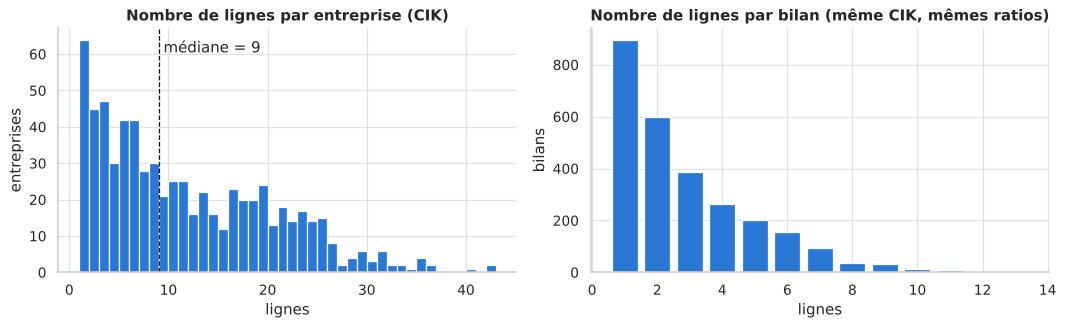

In [8]:
lignes_par_cik = df.groupby("CIK").size()
lignes_par_bilan = df.groupby("bilan_id").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(lignes_par_cik, bins=range(1, lignes_par_cik.max() + 2), color=C_IG, edgecolor="white")
axes[0].set(title="Nombre de lignes par entreprise (CIK)", xlabel="lignes", ylabel="entreprises")
axes[0].axvline(lignes_par_cik.median(), color="#0b0b0b", ls="--", lw=1)
axes[0].text(lignes_par_cik.median() + 0.5, axes[0].get_ylim()[1] * 0.9, f"médiane = {lignes_par_cik.median():.0f}")
vc = lignes_par_bilan.value_counts().sort_index()
axes[1].bar(vc.index, vc.values, color=C_IG, edgecolor="white")
axes[1].set(title="Nombre de lignes par bilan (même CIK, mêmes ratios)", xlabel="lignes", ylabel="bilans")
plt.tight_layout(); plt.show()

print(lignes_par_cik.describe().round(1).to_string())

In [9]:
# Table « une ligne par bilan distinct », réutilisée dans les analyses sensibles aux doublons.
# Label du bilan = label majoritaire de ses notations (ex aequo -> SG, par prudence).
bilans = (df.groupby("bilan_id")
            .agg(**{c: (c, "first") for c in RATIOS},
                 CIK=("CIK", "first"), Sector=("Sector", "first"),
                 part_IG=("Binary Rating", "mean"), nb_notations=("Binary Rating", "size"))
            .reset_index(drop=True))
bilans["Cible"] = np.where(bilans["part_IG"] > 0.5, "IG", "SG")
print(f"{len(bilans)} bilans distincts — répartition :",
      bilans["Cible"].value_counts(normalize=True).round(3).to_dict())

2694 bilans distincts — répartition : {'IG': 0.57, 'SG': 0.43}


### Interprétation : pourquoi le split doit se faire par entreprise

- **Rappel** : le **CIK** (*Central Index Key*) est l'identifiant unique attribué à chaque entreprise par la SEC, le régulateur boursier américain.
- **Le nom n'est pas un identifiant fiable.** 430 des 686 CIK apparaissent sous plusieurs noms (« Inc » / « Inc. », majuscules, filiales). L'exemple ci-dessus montre même un CIK qui regroupe plusieurs entités du groupe National Grid et une société sans rapport apparent : le rattachement au CIK a probablement été fait par rapprochement de noms par l'auteur du dataset, avec quelques erreurs. **Le CIK reste le meilleur identifiant disponible.** Une fusion abusive de deux entreprises sous un même CIK rend le split simplement plus prudent, sans créer de fuite.
- **Les données sont très répétitives.** Une entreprise apparaît en moyenne 11 fois (médiane 9, max 42). Surtout, il n'y a que **2 694 bilans distincts pour 7 805 lignes** : **89 % des lignes ont un « jumeau »** aux 16 ratios strictement identiques. C'est le même bilan annuel, noté par plusieurs agences ou à plusieurs dates.
- **Conséquence (décision D1).** Avec un découpage aléatoire des lignes, un même bilan se retrouverait à la fois dans le train et dans le test. Le modèle n'aurait qu'à le « reconnaître », et les scores seraient artificiellement gonflés. **Tous les découpages (train / test et folds de validation croisée) se feront donc par CIK** (`GroupShuffleSplit`, `StratifiedGroupKFold`).
- Nous prévoyons de **chiffrer ce biais** en partie modélisation, en comparant les scores obtenus avec un split aléatoire et avec un split par CIK.
- La table `bilans` (une ligne par bilan distinct) construite ci-dessus servira pour toutes les analyses que les doublons fausseraient (information mutuelle, PCA, clustering).
- **Observation** : vue bilan par bilan, la répartition passe à **57 % IG / 43 % SG**, contre 65 % / 35 % sur les lignes. Les entreprises IG sont en effet notées plus souvent (3,3 notations par bilan en moyenne, contre 2,4 pour les SG) : les grandes entreprises solides sont suivies par davantage d'agences. Les doublons **surreprésentent donc les IG** dans les lignes brutes. C'est un point à garder en tête pour interpréter le déséquilibre de classes (section 5).

# 5. Étude de la cible

## 5.1 Cible binaire : Investment Grade vs Speculative Grade

Binary Rating cohérent avec la frontière BBB- / BB+ : True
Cible
IG    0.653
SG    0.347


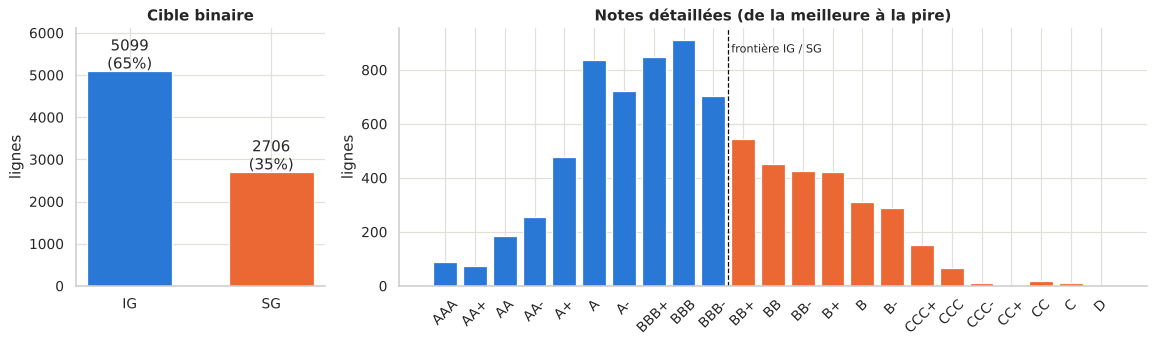

In [10]:
RATING_ORDER = ["AAA", "AA+", "AA", "AA-", "A+", "A", "A-", "BBB+", "BBB", "BBB-",
                "BB+", "BB", "BB-", "B+", "B", "B-", "CCC+", "CCC", "CCC-", "CC+", "CC", "C", "D"]
df["notch"] = df["Rating"].map({r: i for i, r in enumerate(RATING_ORDER)})   # 0 = meilleure note
df["Cible"] = df["Binary Rating"].map({1: "IG", 0: "SG"})

# Vérification : la colonne binaire fournie correspond bien à la frontière BBB- / BB+
coherent = ((df["notch"] <= RATING_ORDER.index("BBB-")) == (df["Binary Rating"] == 1)).all()
print("Binary Rating cohérent avec la frontière BBB- / BB+ :", coherent)

repart = df["Cible"].value_counts()
print((repart / len(df)).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 3]})
axes[0].bar(repart.index, repart.values, color=[PAL_CIBLE[c] for c in repart.index], width=0.6)
for i, v in enumerate(repart.values):
    axes[0].text(i, v + 60, f"{v}\n({v/len(df):.0%})", ha="center")
axes[0].set(title="Cible binaire", ylabel="lignes", ylim=(0, repart.max() * 1.2))

cnt = df["Rating"].value_counts().reindex(RATING_ORDER).fillna(0)
cols = [C_IG if RATING_ORDER.index(r) <= RATING_ORDER.index("BBB-") else C_SG for r in RATING_ORDER]
axes[1].bar(RATING_ORDER, cnt.values, color=cols)
axes[1].axvline(9.5, color="#0b0b0b", ls="--", lw=1)
axes[1].text(9.6, cnt.max() * 0.95, "frontière IG / SG", fontsize=9)
axes[1].set(title="Notes détaillées (de la meilleure à la pire)", ylabel="lignes")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### Interprétation

- La colonne `Binary Rating` fournie est **cohérente** avec la convention de marché (BBB- et mieux = Investment Grade).
- **Déséquilibre modéré : 65 % IG / 35 % SG.** Ce n'est pas un déséquilibre extrême, mais il a deux conséquences :
  - l'**accuracy seule est trompeuse** : un modèle qui répondrait toujours « IG » obtiendrait déjà 65 % ;
  - il faudra des **découpages stratifiés** et tester des corrections (pondération des classes, sur-échantillonnage de type SMOTE **sur le train uniquement**), puis comparer.
- **Choix des métriques (décision D3)** : pour un outil de screening, classer IG une entreprise risquée coûte plus cher à un investisseur qu'une fausse alerte. On suivra donc la **ROC-AUC** et la **PR-AUC** (indépendantes du seuil), le **rappel de la classe SG** (part des entreprises risquées effectivement détectées), le F1 et la balanced accuracy. Les mêmes métriques serviront pour tous les modèles.
- **Notes détaillées** : la distribution est en cloche autour de BBB / A. Les notes extrêmes sont rares (AAA : 90 lignes ; CCC- à D : 34 lignes au total), ce qui justifie des regroupements pour l'extension multiclasse (section 5.3).
- Point d'attention : la masse est forte **de part et d'autre de la frontière** (BBB- : 705 lignes, BB+ : 545). Ce sont les cas les plus difficiles à classer, et c'est là que se concentreront les erreurs.

## 5.2 Les agences sont-elles d'accord entre elles ?

Comparer la part d'Investment Grade par agence serait trompeur : les agences ne notent pas les mêmes entreprises (effet de couverture). On compare donc les agences **sur des bilans identiques**, notés par au moins deux d'entre elles.

In [11]:
AGENCE_COURT = {"Egan-Jones Ratings Company": "Egan-Jones",
                "Standard & Poor's Ratings Services": "S&P",
                "Moody's Investors Service": "Moody's",
                "Fitch Ratings": "Fitch"}
df["Agence"] = df["Rating Agency"].map(AGENCE_COURT).fillna("Autre")

par_agence = df.groupby("Agence").agg(lignes=("Cible", "size"),
                                      part_IG=("Binary Rating", "mean"),
                                      note_moyenne_en_crans=("notch", "mean"))
par_agence.sort_values("lignes", ascending=False).round(2)

,lignes,part_IG,note_moyenne_en_crans
Agence,,,
Egan-Jones,2826,0.77,7.19
S&P,2813,0.59,8.78
Moody's,1636,0.53,9.69
Fitch,477,0.71,8.68
Autre,53,0.98,5.21


In [12]:
# Une ligne par (bilan, agence) : note moyenne si l'agence a noté plusieurs fois le même bilan
pa = df.groupby(["bilan_id", "Agence"]).agg(ig=("Binary Rating", "mean"), notch=("notch", "mean")).reset_index()
lignes = []
for a, b in combinations(["S&P", "Moody's", "Fitch", "Egan-Jones"], 2):
    m = pa[pa.Agence == a].merge(pa[pa.Agence == b], on="bilan_id", suffixes=("_a", "_b"))
    lignes.append({"agence A": a, "agence B": b, "bilans communs": len(m),
                   "accord IG/SG": ((m.ig_a >= .5) == (m.ig_b >= .5)).mean(),
                   "écart moyen (crans, B - A)": (m.notch_b - m.notch_a).mean(),
                   "écart absolu moyen (crans)": (m.notch_b - m.notch_a).abs().mean()})
accord = pd.DataFrame(lignes)
accord.round(3)

,agence A,agence B,bilans communs,accord IG/SG,"écart moyen (crans, B - A)",écart absolu moyen (crans)
0,S&P,Moody's,665,0.944,0.492,1.193
1,S&P,Fitch,220,0.936,0.218,1.174
2,S&P,Egan-Jones,453,0.905,-0.510,1.743
3,Moody's,Fitch,194,0.897,-0.375,1.036
4,Moody's,Egan-Jones,321,0.885,-1.121,1.781
5,Fitch,Egan-Jones,115,0.843,-0.631,1.429


Bilans notés par >= 2 agences : 1231
... dont désaccord IG / SG    : 149 (12.1%)
Lignes dont le même bilan porte des labels IG et SG (toutes agences et dates) : 766
Entreprises ayant changé de catégorie IG/SG sur la période : 131


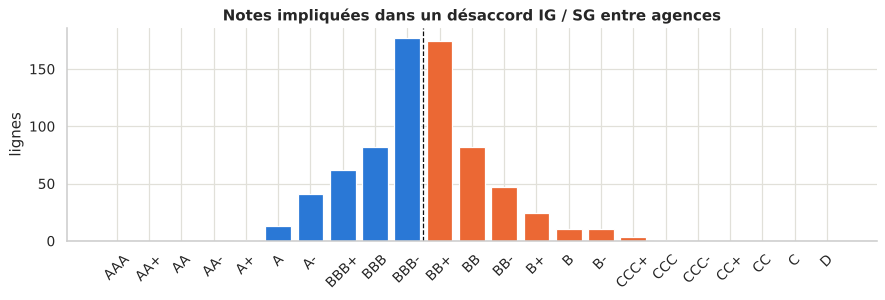

In [13]:
# Où se situent les désaccords IG / SG ?
multi = df.groupby("bilan_id")["Agence"].nunique()
bilans_multi = multi[multi > 1].index
desaccord = df[df.bilan_id.isin(bilans_multi)].groupby("bilan_id")["Binary Rating"].nunique() > 1
lignes_desacc = df[df.bilan_id.isin(desaccord[desaccord].index)]
print(f"Bilans notés par >= 2 agences : {len(bilans_multi)}")
print(f"... dont désaccord IG / SG    : {desaccord.sum()} ({desaccord.mean():.1%})")

fig, ax = plt.subplots(figsize=(10, 3.5))
c = lignes_desacc["Rating"].value_counts().reindex(RATING_ORDER).fillna(0)
ax.bar(RATING_ORDER, c.values, color=[C_IG if i <= 9 else C_SG for i in range(len(RATING_ORDER))])
ax.axvline(9.5, color="#0b0b0b", ls="--", lw=1)
ax.set(title="Notes impliquées dans un désaccord IG / SG entre agences", ylabel="lignes")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

conflit = df.groupby("bilan_id")["Binary Rating"].transform("nunique") > 1
print(f"Lignes dont le même bilan porte des labels IG et SG (toutes agences et dates) : {conflit.sum()}")
print(f"Entreprises ayant changé de catégorie IG/SG sur la période : "
      f"{(df.groupby('CIK')['Binary Rating'].nunique() > 1).sum()}")

### Interprétation : les agences ne disent pas toujours la même chose

- **Ne pas se fier à la part brute d'IG par agence** (Egan-Jones 77 %, Fitch 71 %, S&P 59 %, Moody's 53 %). Elle mélange le biais de notation et un **effet de couverture** : les agences ne notent pas le même panel d'entreprises.
- **Sur des bilans identiques**, les agences sont d'accord sur IG / SG dans **84 à 94 % des cas**. S&P et Moody's sont les plus alignées (94,4 % sur 665 bilans communs).
- **Biais systématique** : à bilan égal, Egan-Jones note en moyenne **0,5 cran au-dessus de S&P** et **1,1 cran au-dessus de Moody's**. L'ordre de « générosité » est : Egan-Jones > Fitch ≈ S&P > Moody's.
  - **Ce n'est pas un effet du mode de rémunération.** Egan-Jones est payée par les investisseurs (*investor-pays*), les trois grandes par les entreprises notées (*issuer-pays*). Si le conflit d'intérêts des agences *issuer-pays* gonflait leurs notes, Egan-Jones devrait noter *plus sévèrement*. On observe l'inverse.
  - **Ce résultat est cohérent avec la littérature** : une étude mesure un écart de +0,66 cran entre Egan-Jones et Moody's (+0,93 sur les entreprises IG) et y voit un argument contre l'hypothèse d'inflation des notes par les agences *issuer-pays* ([Financial Innovation, 2021](https://link.springer.com/doi/10.1186/s40854-021-00263-z)).
  - **Explication avancée par Beaver, Shakespeare et Soliman** ([Stanford GSB](https://www.gsb.stanford.edu/insights/research-bond-rating-system-isnt-broken)) : les notes de Moody's et S&P ont un rôle **quasi réglementaire** (de nombreux investisseurs institutionnels doivent vendre une obligation qui passe sous la catégorie IG). Ces agences notent donc de façon plus **conservatrice et stable**, « à travers le cycle », alors qu'Egan-Jones produit des notes plus réactives au marché.
- **Les désaccords se concentrent sur la frontière.** Sur les 1 231 bilans notés par au moins deux agences, 149 (12,1 %) sont classés IG par l'une et SG par l'autre, presque toujours autour de BBB- / BB+.
- **Bruit irréductible dans la cible.** 766 lignes ont un bilan identique à une autre ligne mais un label IG / SG différent, et 131 entreprises changent de catégorie sur la période. Sans information supplémentaire, aucun modèle ne peut classer correctement toutes ces lignes : **un score parfait est impossible**.

**Décision D2.** Nous gardons **toutes les lignes** et ajoutons **l'agence comme variable explicative** (les 3 agences marginales, 53 lignes, sont regroupées en « Autre »). Le modèle peut ainsi apprendre le décalage entre agences au lieu de le subir comme du bruit. En usage « screening », on fixera une agence de référence (par exemple S&P) pour répondre à la question « comment S&P noterait-elle cette entreprise ? ».
Un **pipeline de comparaison sans l'agence** sera aussi entraîné : l'écart de performance mesurera ce que l'agence apporte.
Alternatives écartées : ne garder qu'une agence (cible plus propre, mais 64 % des données perdues) ; une note consensus par bilan (plus de doublons, mais l'information sur l'agence est perdue).

## 5.3 Évolution dans le temps et regroupement multiclasse (extension)

Year,2010,2011,2012,2013,2014,2015,2016
groupe,,,,,,,
Autres secteurs,0.73,0.64,0.60,0.65,0.69,0.69,0.57
Énergie,NaN,0.63,0.64,0.73,0.77,0.60,0.43


Year,2010,2011,2012,2013,2014,2015,2016
lignes,41.000,325.00,1071.000,1387.000,1944.000,2062.000,975.000
part_IG,0.732,0.64,0.601,0.657,0.694,0.685,0.557


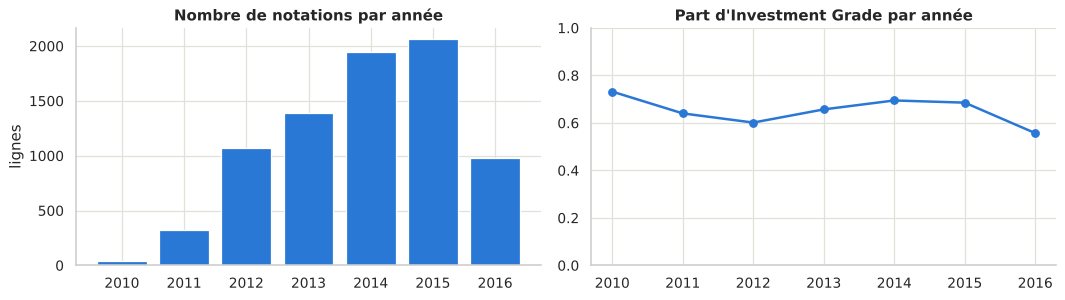

In [14]:
par_an = df.groupby("Year").agg(lignes=("Cible", "size"), part_IG=("Binary Rating", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].bar(par_an.index, par_an["lignes"], color=C_IG)
axes[0].set(title="Nombre de notations par année", ylabel="lignes")
axes[1].plot(par_an.index, par_an["part_IG"], marker="o", color=C_IG, lw=2)
axes[1].set(title="Part d'Investment Grade par année", ylim=(0, 1))
plt.tight_layout(); plt.show()

# Hypothèse : la baisse de 2016 est-elle liée au secteur de l'énergie (chute du pétrole 2014-2016) ?
energie = df.assign(groupe=np.where(df.Sector == "Enrgy", "Énergie", "Autres secteurs"))
display(energie.pivot_table(index="groupe", columns="Year", values="Binary Rating", aggfunc="mean").round(2))
par_an.round(3).T

In [15]:
# Proposition de regroupement pour l'extension multiclasse
def niveau_risque(note):
    if note in ["AAA", "AA+", "AA", "AA-"]: return "1 - AAA à AA (risque minimal)"
    if note in ["A+", "A", "A-"]: return "2 - A (faible)"
    if note in ["BBB+", "BBB", "BBB-"]: return "3 - BBB (modéré, limite IG)"
    if note in ["BB+", "BB", "BB-"]: return "4 - BB (spéculatif)"
    return "5 - B et moins (très spéculatif)"

df["Niveau_risque"] = df["Rating"].map(niveau_risque)
df["Niveau_risque"].value_counts().sort_index().to_frame("lignes").assign(
    part=lambda t: (t["lignes"] / len(df)).round(3))

,lignes,part
Niveau_risque,,
1 - AAA à AA (risque minimal),602,0.077
2 - A (faible),2036,0.261
"3 - BBB (modéré, limite IG)",2461,0.315
4 - BB (spéculatif),1425,0.183
5 - B et moins (très spéculatif),1281,0.164


### Interprétation

- **Volume** : 2012-2016 concentrent l'essentiel des données. 2010 n'a que 41 lignes (début de période incomplet).
- **Instabilité dans le temps** : la part d'IG passe de 69 % en 2014 à 56 % en 2016. La baisse est **plus forte dans l'énergie** (77 % → 43 %), ce qui est cohérent avec la chute des prix du pétrole de 2014-2016 et la vague de dégradations qui a suivi. Elle touche aussi les autres secteurs (69 % → 57 %).
  → Hypothèse : la relation ratios → note n'est pas parfaitement stable dans le temps. Nous testerons en complément un **split temporel** (entraînement ≤ 2014, test 2015-2016) pour mesurer la robustesse du modèle. L'année pourra aussi être testée comme variable.
- **Extension multiclasse** : le regroupement en 5 niveaux donne des classes exploitables (de 602 à 2 461 lignes), alors que les 23 notes brutes comptaient des classes de 1 à 5 lignes. Ce découpage respecte la frontière IG / SG (niveaux 1-3 = IG, 4-5 = SG) : la tâche binaire et la tâche multiclasse restent donc cohérentes entre elles.

# 6. Distributions, valeurs extrêmes et mise à l'échelle

## 6.1 Distributions brutes

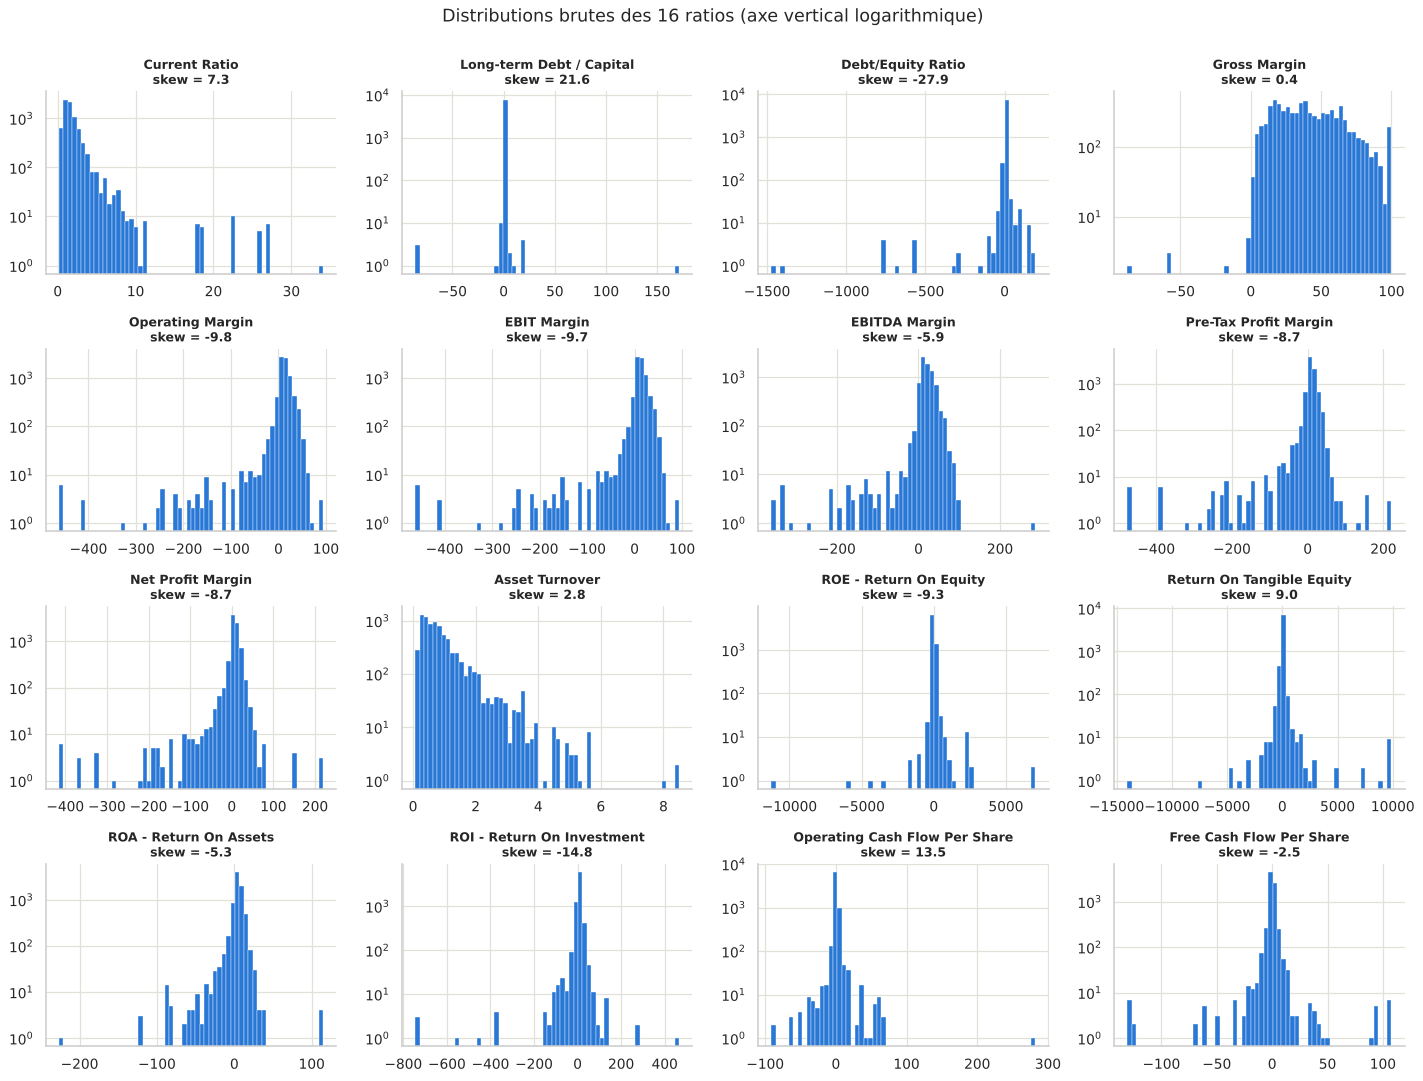

In [16]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), RATIOS):
    ax.hist(df[col], bins=60, color=C_IG, edgecolor="white", linewidth=0.3)
    ax.set_yscale("log")
    ax.set_title(f"{col}\nskew = {df[col].skew():.1f}", fontsize=10)
plt.suptitle("Distributions brutes des 16 ratios (axe vertical logarithmique)", fontsize=14, y=1.00)
plt.tight_layout(); plt.show()

### Interprétation

- Presque toutes les distributions sont **très concentrées avec des queues extrêmes**, d'un ou des deux côtés : l'échelle verticale est logarithmique, sinon les queues seraient invisibles. Seules la Gross Margin (bornée à 100 %) et, dans une moindre mesure, l'Asset Turnover ont une forme « raisonnable ».
- Origine économique de ces extrêmes : **un ratio dont le dénominateur s'approche de zéro explose**. Le ROE, par exemple, divise le résultat par des fonds propres qui peuvent être quasi nuls ou négatifs. Ces valeurs ne sont donc pas des erreurs de saisie, mais elles rendent les distances euclidiennes et les modèles linéaires non transformés inutilisables.

## 6.2 Valeurs extrêmes : combien, et chez qui ?

On compte les valeurs hors des bornes de Tukey (Q1 − 3·IQR, Q3 + 3·IQR, seuil « extrême ») et on regarde si elles concernent davantage les entreprises Speculative Grade.

In [17]:
q1, q3 = df[RATIOS].quantile(.25), df[RATIOS].quantile(.75)
iqr = q3 - q1
extreme = (df[RATIOS] < q1 - 3 * iqr) | (df[RATIOS] > q3 + 3 * iqr)

out = pd.DataFrame({
    "nb_extrêmes": extreme.sum(),
    "part_extrêmes": extreme.mean(),
    "part_SG_parmi_extrêmes": [df.loc[extreme[c], "Binary Rating"].eq(0).mean() for c in RATIOS],
}).sort_values("nb_extrêmes", ascending=False)
print(f"Part de SG dans tout le dataset : {df['Binary Rating'].eq(0).mean():.1%}")
ligne_ext = extreme.any(axis=1)
print(f"Lignes avec au moins une valeur extrême : {ligne_ext.sum()} ({ligne_ext.mean():.1%}) "
      f"— dont SG : {df.loc[ligne_ext, 'Binary Rating'].eq(0).mean():.1%}")
out.round(3)

Part de SG dans tout le dataset : 34.7%
Lignes avec au moins une valeur extrême : 2255 (28.9%) — dont SG : 50.7%


,nb_extrêmes,part_extrêmes,part_SG_parmi_extrêmes
Return On Tangible Equity,725,0.093,0.353
Debt/Equity Ratio,639,0.082,0.717
ROE - Return On Equity,603,0.077,0.599
Free Cash Flow Per Share,390,0.050,0.551
Operating Cash Flow Per Share,368,0.047,0.554
Net Profit Margin,238,0.030,0.685
Current Ratio,235,0.030,0.668
ROI - Return On Investment,232,0.030,0.616
Pre-Tax Profit Margin,194,0.025,0.722
ROA - Return On Assets,183,0.023,0.689


In [18]:
# Fonds propres négatifs : un cas particulier de « valeur extrême » qui a un sens économique
neg_eq = df["Debt/Equity Ratio"] < 0
print(f"Lignes avec Debt/Equity < 0 (fonds propres négatifs) : {neg_eq.sum()}")
print(f"Part de SG parmi elles : {df.loc[neg_eq, 'Binary Rating'].eq(0).mean():.1%} "
      f"(contre {df.loc[~neg_eq, 'Binary Rating'].eq(0).mean():.1%} ailleurs)")
print(f"Part IG parmi elles : {df.loc[neg_eq, 'Binary Rating'].mean():.1%}")
print("Secteurs les plus représentés :", df.loc[neg_eq, "Sector"].value_counts().head(4).to_dict())

Lignes avec Debt/Equity < 0 (fonds propres négatifs) : 299
Part de SG parmi elles : 77.9% (contre 32.9% ailleurs)
Part IG parmi elles : 22.1%
Secteurs les plus représentés : {'Shops': 47, 'BusEq': 44, 'Other': 44, 'Durbl': 35}


### Interprétation : les valeurs extrêmes sont informatives

- **29 % des lignes** ont au moins une valeur extrême (critère de Tukey à 3 IQR). Les supprimer ferait perdre près d'un tiers des données.
- Surtout, **ces lignes sont nettement plus risquées** : 51 % de SG, contre 35 % en moyenne. Les extrêmes sont particulièrement associés au SG pour les ratios d'endettement (Debt/Equity : 72 %, LT Debt / Capital : 73 %) et pour les marges. **Supprimer les extrêmes reviendrait donc à retirer une partie des entreprises en difficulté**, celles que l'outil doit précisément détecter.
- Exceptions instructives :
  - **Return On Tangible Equity** : ses extrêmes ne sont pas plus risqués que la moyenne (35 % de SG). Ils viennent surtout d'un *goodwill* important qui rend les fonds propres tangibles proches de zéro ou négatifs (entreprises qui ont fait beaucoup d'acquisitions). C'est un ratio bruité.
  - **Asset Turnover** : ses extrêmes sont à 89 % IG. Ce sont des distributeurs à forte rotation des actifs, pas des entreprises en difficulté.
- **Fonds propres négatifs (Debt/Equity < 0)** : 299 lignes, à **78 % SG** (contre 33 % ailleurs). C'est un signal de détresse fort. Mais 22 % de ces entreprises restent IG, et elles sont **très rentables** (ROA médian de 14,3 %, contre 4,8 % pour l'ensemble du dataset). Ce sont probablement des sociétés qui ont racheté massivement leurs propres actions, ce qui a fait passer leurs fonds propres comptables sous zéro sans dégrader leur solvabilité. Un ratio isolé ne suffit donc pas : il faut le lire avec la rentabilité.

**Décision D4** : on **garde toutes les lignes** et on traite les extrêmes **dans le pipeline**, avec des paramètres ajustés sur le train uniquement. Les variantes de transformation comparées en section 6.3 seront testées comme des pipelines différents.

## 6.3 Comparaison de transformations

Plusieurs stratégies sont possibles pour rendre ces distributions exploitables. On les compare visuellement sur trois ratios représentatifs. Les paramètres (percentiles, quantiles) seront **toujours ajustés sur le train uniquement** lors de la modélisation ; ici, l'objectif est seulement de visualiser leur effet.

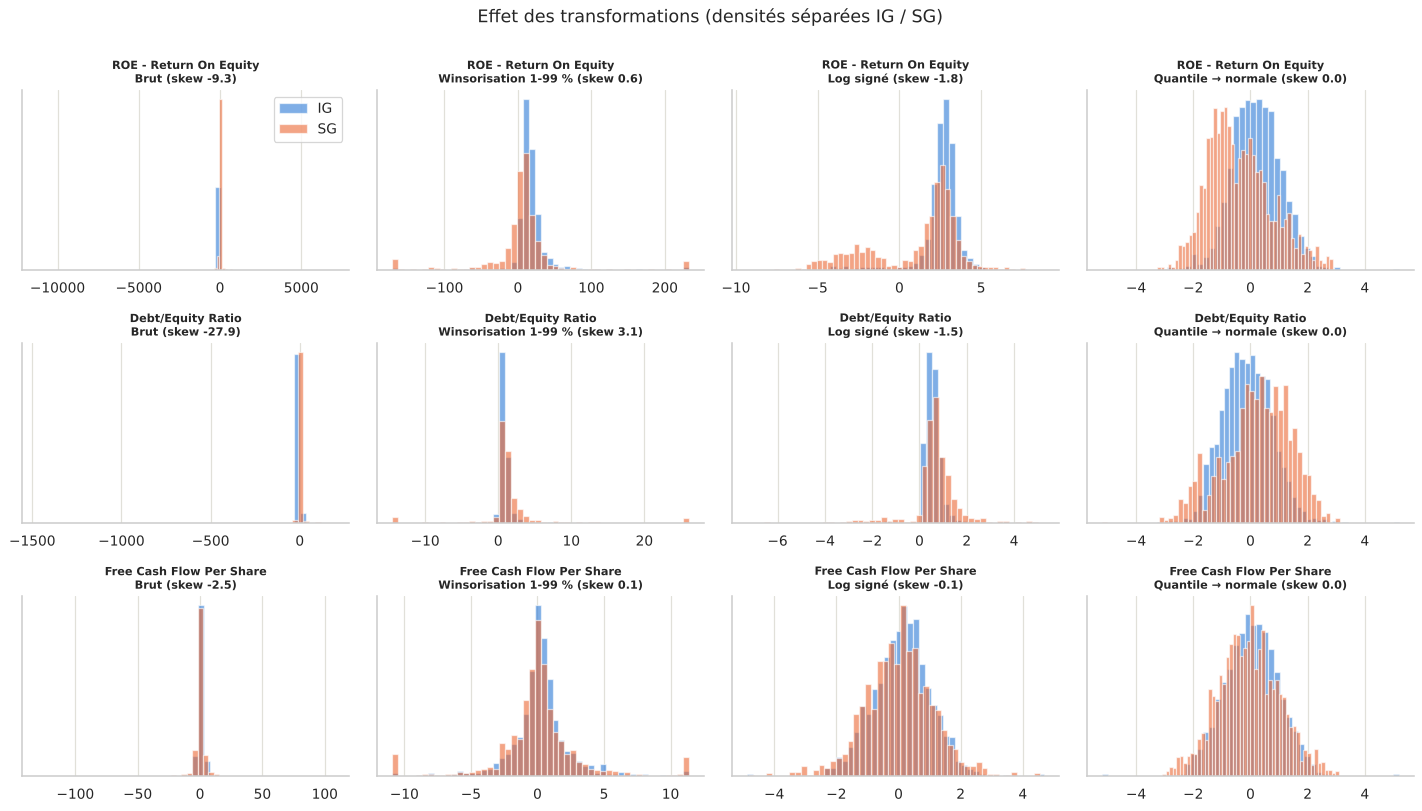

In [19]:
def winsorise(s, bas=0.01, haut=0.99):
    return s.clip(s.quantile(bas), s.quantile(haut))

def log_signe(s):
    return np.sign(s) * np.log1p(np.abs(s))

qt = QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=SEED)
transfos = {
    "Brut": lambda s: s,
    "Winsorisation 1-99 %": winsorise,
    "Log signé": log_signe,
    "Quantile → normale": lambda s: pd.Series(qt.fit_transform(s.to_frame()).ravel(), index=s.index),
}
exemples = ["ROE - Return On Equity", "Debt/Equity Ratio", "Free Cash Flow Per Share"]

fig, axes = plt.subplots(len(exemples), len(transfos), figsize=(16, 9))
for i, col in enumerate(exemples):
    for j, (nom, f) in enumerate(transfos.items()):
        v = f(df[col])
        axes[i, j].hist(v[df.Cible == "IG"], bins=50, alpha=.6, color=C_IG, label="IG", density=True)
        axes[i, j].hist(v[df.Cible == "SG"], bins=50, alpha=.6, color=C_SG, label="SG", density=True)
        axes[i, j].set_title(f"{col[:24]}\n{nom} (skew {v.skew():.1f})", fontsize=9)
        axes[i, j].set_yticks([])
axes[0, 0].legend()
plt.suptitle("Effet des transformations (densités séparées IG / SG)", fontsize=14, y=1.00)
plt.tight_layout(); plt.show()

In [20]:
# Pouvoir discriminant univarié : test de Mann-Whitney + taille d'effet (AUC univariée)
# Avantage : basé sur les rangs, donc insensible aux valeurs extrêmes et aux transformations monotones.
res = []
for col in RATIOS:
    ig, sg = df.loc[df.Cible == "IG", col], df.loc[df.Cible == "SG", col]
    u, p = stats.mannwhitneyu(ig, sg, alternative="two-sided")
    auc = u / (len(ig) * len(sg))                 # P(valeur IG > valeur SG)
    res.append({"ratio": col, "famille": FAMILLE[col],
                "médiane IG": ig.median(), "médiane SG": sg.median(),
                "AUC univariée": auc, "force (|AUC - 0,5|)": abs(auc - .5), "p-valeur": p})
univ = pd.DataFrame(res).sort_values("force (|AUC - 0,5|)", ascending=False).set_index("ratio")
univ.round(3)

,famille,médiane IG,médiane SG,AUC univariée,"force (|AUC - 0,5|)",p-valeur
ratio,,,,,,
Pre-Tax Profit Margin,Marge,12.248,4.434,0.745,0.245,0.000
Net Profit Margin,Marge,8.769,3.409,0.731,0.231,0.000
ROI - Return On Investment,Rentabilité,9.118,3.997,0.730,0.230,0.000
ROA - Return On Assets,Rentabilité,5.859,2.685,0.714,0.214,0.000
EBIT Margin,Marge,14.336,7.546,0.692,0.192,0.000
Long-term Debt / Capital,Endettement,0.380,0.508,0.308,0.192,0.000
Operating Margin,Marge,14.336,7.546,0.691,0.191,0.000
ROE - Return On Equity,Rentabilité,14.472,7.533,0.679,0.179,0.000
EBITDA Margin,Marge,20.637,13.330,0.630,0.130,0.000


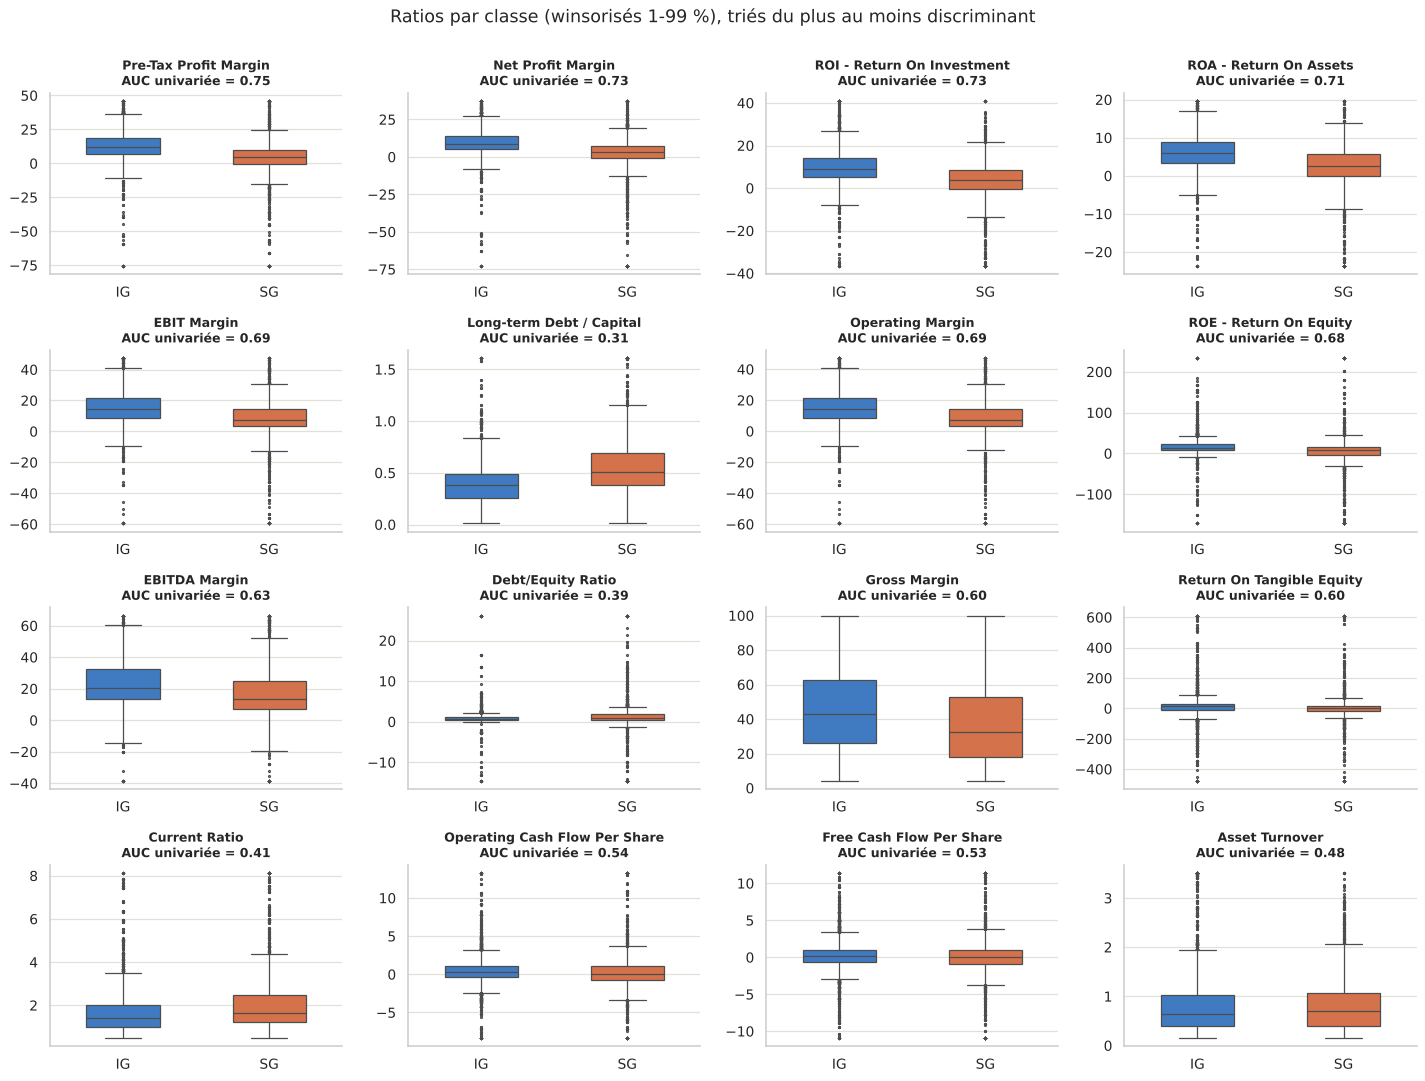

In [21]:
# Boîtes à moustaches par classe, après winsorisation (pour que l'échelle reste lisible)
dfw = df[RATIOS].apply(winsorise)
dfw["Cible"] = df["Cible"]
ordre = univ.index.tolist()
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), ordre):
    sns.boxplot(data=dfw, x="Cible", y=col, hue="Cible", order=["IG", "SG"], palette=PAL_CIBLE,
                ax=ax, fliersize=1.5, width=.5, legend=False)
    ax.set_title(f"{col}\nAUC univariée = {univ.loc[col, 'AUC univariée']:.2f}", fontsize=10)
    ax.set(xlabel="", ylabel="")
plt.suptitle("Ratios par classe (winsorisés 1-99 %), triés du plus au moins discriminant", fontsize=14, y=1.00)
plt.tight_layout(); plt.show()

### Interprétation et stratégie de mise à l'échelle

**Comparaison des transformations (graphique ci-dessus) :**

| Transformation | Effet | Limites |
|---|---|---|
| Brut + `StandardScaler` | aucun traitement des extrêmes | moyenne et écart-type écrasés par les extrêmes : inutilisable pour KNN, SVM, régression logistique |
| `RobustScaler` (médiane, IQR) | centrage robuste | ne réduit pas les queues |
| Winsorisation 1-99 % | coupe les queues, garde l'ordre et l'échelle | des pics artificiels aux bornes ; le seuil est arbitraire |
| Log signé | compresse les queues, garde le signe | fait apparaître une bimodalité (ROE positif / négatif) ; asymétrie résiduelle |
| Quantile → normale | distribution normale parfaite, robuste | perd l'information de distance (seul le rang compte) |

- **Le log signé révèle une structure utile** : pour le ROE, il sépare un groupe à ROE négatif, très majoritairement SG. Ce n'est pas un défaut de la transformation, mais une **piste de feature** (indicateur « ROE < 0 », « résultat négatif »).
- **Piège identifié sur le Debt/Equity** : toutes ces transformations sont monotones et rangent donc les fonds propres négatifs (situation la plus risquée) **à côté des entreprises les moins endettées** (valeurs faibles). L'ordre numérique ne correspond pas à l'ordre économique. → Il faudra ajouter un **indicateur « fonds propres négatifs »** pour que les modèles linéaires puissent distinguer ces cas.
- **Pour les modèles à base d'arbres** (Random Forest, boosting), aucune transformation n'est nécessaire : ils ne dépendent que de l'ordre des valeurs. C'est un argument en leur faveur sur ce dataset.

**Pouvoir discriminant univarié (AUC de Mann-Whitney, insensible aux extrêmes)** :
- *Comment lire l'AUC univariée* : on tire au hasard une entreprise IG et une entreprise SG ; l'AUC est la probabilité que l'IG ait la valeur la plus élevée pour ce ratio. **0,5** = le ratio ne sépare pas les classes (pile ou face) ; **proche de 1** = les IG ont presque toujours la valeur la plus haute ; **proche de 0** = ce sont les SG. La « force » |AUC − 0,5| permet de comparer les ratios quel que soit le sens de l'effet.
- Les plus discriminants sont les **ratios de rentabilité nette** : Pre-Tax Profit Margin (AUC 0,75), Net Profit Margin (0,73), ROI (0,73), ROA (0,71), puis l'**endettement** (LT Debt / Capital, 0,69 dans le sens « plus endetté = plus risqué »). C'est cohérent avec la finance : les agences regardent d'abord la capacité à dégager des profits et le poids de la dette.
- Le **Current Ratio** est légèrement plus élevé chez les SG (AUC 0,41). C'est contre-intuitif : on l'analyse en détail en section 6.4.
- Les **cash-flows par action** (AUC 0,53-0,54) et l'**Asset Turnover** (0,48) ne discriminent presque pas. Pour les cash-flows, c'est attendu : un montant *par action* dépend du nombre d'actions émises et n'est donc pas comparable d'une entreprise à l'autre.

**Deux réserves méthodologiques** :
- Les **p-valeurs** (toutes quasi nulles) sont **trop optimistes** : le test de Mann-Whitney suppose des observations indépendantes, or 89 % des lignes ont un jumeau (section 4.2). L'effectif « réel » est bien plus petit que 7 805. On s'appuie donc sur l'**AUC** (une taille d'effet), pas sur la p-valeur, pour classer les ratios.
- Ces analyses portent sur **tout le dataset**, ce qui est normal pour une exploration. En revanche, aucune variable n'est supprimée sur cette base : les choix définitifs de variables et de transformations se feront **dans la validation croisée, sur le train uniquement**, pour ne pas introduire de fuite.

**Stratégie retenue** : on comparera au moins deux variantes de prétraitement dans les pipelines, **winsorisation + `StandardScaler`** et **`QuantileTransformer`**, toutes deux ajustées sur le train, avec ajout des indicateurs de signe. Les modèles à arbres seront aussi testés sur les ratios bruts.

## 6.4 Zoom sur une surprise : le Current Ratio

Le **Current Ratio** = actifs à court terme (trésorerie, créances clients, stocks) ÷ dettes à court terme (fournisseurs, salaires, emprunts à moins d'un an). Un ratio de 2 signifie « 2 € disponibles pour chaque euro à payer dans l'année ».

L'intuition des manuels : **plus il est élevé, plus l'entreprise est sûre**. Or la section 6.3 montre l'inverse (AUC univariée de 0,41 : le ratio est plus élevé chez les SG). On vérifie si cet effet est réel ou s'il vient seulement de la composition des secteurs (par exemple, les *utilities*, très sûres, ont structurellement un ratio bas).

Pour ne pas compter plusieurs fois un même bilan, l'analyse porte sur la table `bilans` (section 4.2).

,médiane,part_sous_1
Cible,,
IG,1.47,0.22
SG,1.68,0.14


,médiane IG,médiane SG,bilans,part IG,AUC dans le secteur
Sector,,,,,
NoDur,1.45,2.20,184,0.71,0.25
Telcm,0.83,1.52,135,0.39,0.29
Chems,1.91,2.43,111,0.60,0.30
Shops,1.30,1.54,281,0.49,0.39
Utils,0.97,1.06,255,0.85,0.41
Manuf,2.01,2.12,364,0.53,0.43
Other,1.46,1.54,446,0.46,0.45
Durbl,1.53,1.61,78,0.44,0.49
BusEq,2.01,1.78,362,0.59,0.51


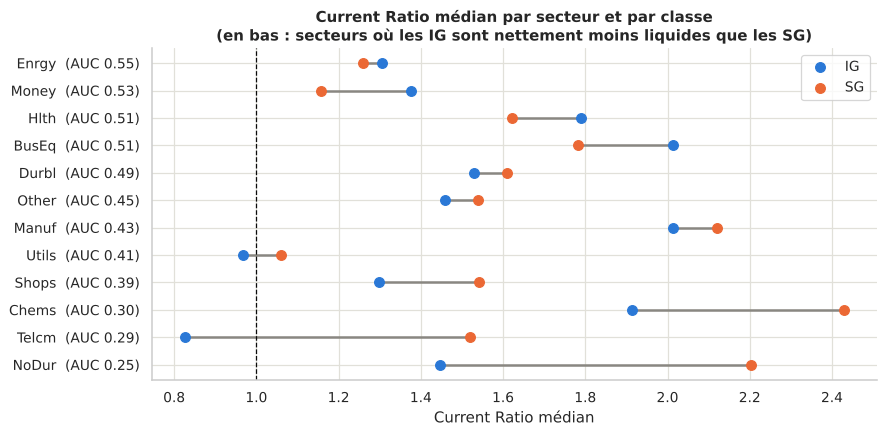

In [22]:
CR = "Current Ratio"
glob = bilans.groupby("Cible")[CR].agg(médiane="median", part_sous_1=lambda s: (s < 1).mean())
display(glob.round(2))

def auc_univ(g):
    a, b = g.loc[g.Cible == "IG", CR], g.loc[g.Cible == "SG", CR]
    if min(len(a), len(b)) < 10:
        return np.nan
    return stats.mannwhitneyu(a, b).statistic / (len(a) * len(b))

par_secteur = (bilans.groupby(["Sector", "Cible"])[CR].median().unstack()
               .assign(bilans=bilans.groupby("Sector").size(),
                       part_IG=bilans.groupby("Sector")["Cible"].apply(lambda s: (s == "IG").mean()),
                       AUC_dans_le_secteur=bilans.groupby("Sector")[["Cible", CR]].apply(auc_univ))
               .sort_values("AUC_dans_le_secteur"))
par_secteur.columns = ["médiane IG", "médiane SG", "bilans", "part IG", "AUC dans le secteur"]

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(par_secteur))
ax.hlines(y, par_secteur["médiane IG"], par_secteur["médiane SG"], color=C_NEUTRE, lw=2)
ax.scatter(par_secteur["médiane IG"], y, color=C_IG, s=60, label="IG", zorder=3)
ax.scatter(par_secteur["médiane SG"], y, color=C_SG, s=60, label="SG", zorder=3)
ax.set_yticks(y, [f"{s}  (AUC {a:.2f})" for s, a in zip(par_secteur.index, par_secteur["AUC dans le secteur"])])
ax.axvline(1, color="#0b0b0b", ls="--", lw=1)
ax.set(title="Current Ratio médian par secteur et par classe\n(en bas : secteurs où les IG sont nettement moins liquides que les SG)",
       xlabel="Current Ratio médian")
ax.legend()
plt.tight_layout(); plt.show()
par_secteur.round(2)

### Interprétation : un effet réel, qui s'explique économiquement

**Le constat se confirme sur les bilans distincts** : Current Ratio médian de **1,47 chez les IG contre 1,68 chez les SG**, et **22 % des IG sont sous 1**, contre 14 % des SG. Les entreprises les plus solides ont donc *moins* de liquidités par rapport à leurs dettes à court terme.

**Ce n'est pas seulement un effet de composition des secteurs.** À l'intérieur de chaque secteur :
- l'effet est **net** dans les biens de consommation courante (NoDur : médiane 1,45 chez les IG contre 2,20 chez les SG, AUC 0,25), les télécoms (0,83 contre 1,52), la chimie et la distribution (Shops) ;
- il est **absent** dans l'informatique (BusEq), la santé, la finance et l'énergie (AUC entre 0,51 et 0,55).

**Trois explications complémentaires :**
1. **L'accès au crédit (motif de précaution).** Une entreprise IG peut lever des fonds rapidement et à bas coût (marchés obligataires, lignes de crédit bancaires confirmées) : garder de la trésorerie inutilisée lui coûte de l'argent. Une entreprise fragile n'est pas sûre de trouver un prêteur le jour où elle en aura besoin : elle garde un **coussin de sécurité**. C'est un résultat classique de la finance d'entreprise : les entreprises qui ont un accès difficile aux marchés détiennent davantage de trésorerie (Opler, Pinkowitz, Stulz et Williamson, 1999).
2. **Le pouvoir de négociation.** Une grande entreprise de grande consommation ou de distribution se fait payer rapidement par ses clients mais paie ses fournisseurs à 60 ou 90 jours. Ses dettes fournisseurs (au dénominateur) sont gonflées, et son Current Ratio baisse. Ici, un ratio bas est un **signe de force**, pas de faiblesse. C'est cohérent avec l'effet très marqué dans NoDur.
3. **Des secteurs sûrs à ratio structurellement bas.** Les *utilities* (85 % IG) ont un ratio médian autour de 1 : leurs revenus réguliers et réglementés les dispensent de réserves importantes.

**Conséquences pour la modélisation :**
- L'effet est **faible** (AUC 0,41) : le Current Ratio n'est pas un bon prédicteur à lui seul.
- Son sens **dépend du secteur** : c'est un argument pour des modèles capables de capter des **interactions** (arbres, boosting) et pour des variables **relatives au secteur** (ratio − médiane du secteur, calculée sur le train).
- Plus généralement, on ne plaque pas une intuition de manuel sur les données : on vérifie, et quand le résultat est contre-intuitif, on cherche son explication économique.

# 7. Corrélations, variables catégorielles et sélection

## 7.1 Redondance entre ratios

**Pourquoi regarder les corrélations ?** Si deux ratios disent presque la même chose, les garder tous les deux n'apporte pas d'information nouvelle. Pire, cela gêne les modèles linéaires : c'est la **multicolinéarité**. Le modèle ne sait plus à quel ratio attribuer l'effet, et ses coefficients deviennent instables et difficiles à interpréter.

**Quelle corrélation ?** La corrélation de **Pearson** mesure une relation *linéaire* et se laisse dominer par quelques valeurs extrêmes (section 6). On utilise celle de **Spearman**, qui fait le même calcul sur les **rangs** : elle mesure si deux ratios « montent ensemble », quelle que soit la forme de la relation, et elle est insensible aux extrêmes. Elle va de −1 (l'un monte quand l'autre descend) à +1 (ils montent ensemble), 0 signifiant aucun lien.

Paires de ratios avec |rho| >= 0,85 : 7


,ratio A,ratio B,rho
69,Operating Margin,EBIT Margin,0.999
205,ROA - Return On Assets,ROI - Return On Investment,0.957
71,Operating Margin,Pre-Tax Profit Margin,0.928
87,EBIT Margin,Pre-Tax Profit Margin,0.928
120,Pre-Tax Profit Margin,Net Profit Margin,0.913
86,EBIT Margin,EBITDA Margin,0.883
70,Operating Margin,EBITDA Margin,0.881


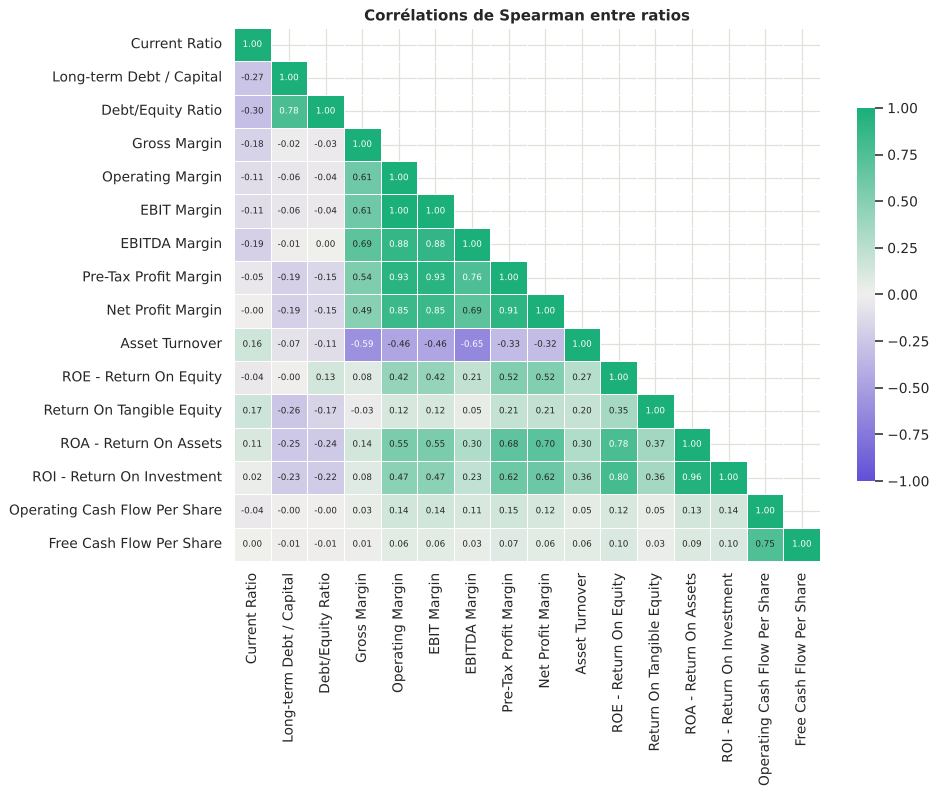

In [23]:
corr = df[RATIOS].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap=CMAP_DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=.5, linecolor="white", cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Corrélations de Spearman entre ratios")
plt.tight_layout(); plt.show()

paires = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
          .rename("rho").reset_index().rename(columns={"level_0": "ratio A", "level_1": "ratio B"}))
paires = paires.loc[paires["rho"].abs() >= 0.85].sort_values("rho", ascending=False)
print(f"Paires de ratios avec |rho| >= 0,85 : {len(paires)}")
paires.round(3)

,famille,Spearman avec la cible (bilans),IM sur les lignes (biaisée),IM sur les bilans distincts
Pre-Tax Profit Margin,Marge,0.400,0.350,0.091
Net Profit Margin,Marge,0.387,0.348,0.088
ROI - Return On Investment,Rentabilité,0.371,0.351,0.081
ROA - Return On Assets,Rentabilité,0.346,0.335,0.079
Long-term Debt / Capital,Endettement,-0.313,0.309,0.069
ROE - Return On Equity,Rentabilité,0.277,0.330,0.066
Return On Tangible Equity,Rentabilité,0.157,0.329,0.047
EBITDA Margin,Marge,0.207,0.328,0.045
Debt/Equity Ratio,Endettement,-0.201,0.318,0.038
EBIT Margin,Marge,0.302,0.323,0.036


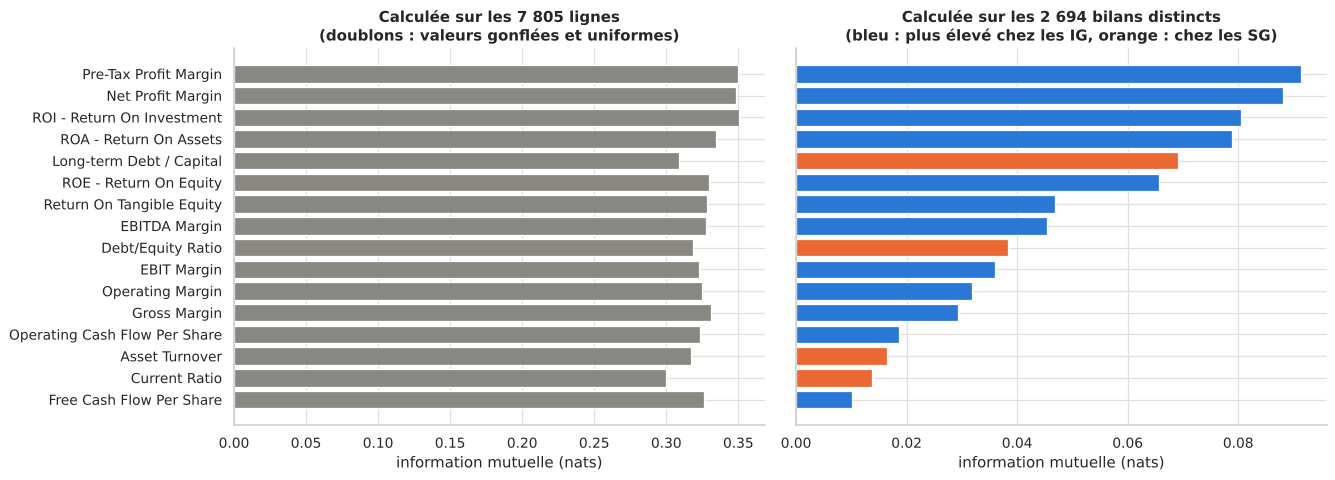

In [24]:
# Information mutuelle avec la cible (capte aussi les relations non linéaires).
# L'estimateur de scikit-learn repose sur les plus proches voisins : on le calcule
# sur les 7 805 lignes PUIS sur les 2 694 bilans distincts, pour voir l'effet des doublons.
y_bil = (bilans["Cible"] == "IG").astype(int)
mi_lignes = mutual_info_classif(df[RATIOS], df["Binary Rating"], random_state=SEED)
mi_bilans = mutual_info_classif(bilans[RATIOS], y_bil, random_state=SEED)
lien = pd.DataFrame({"famille": [FAMILLE[c] for c in RATIOS],
                     "Spearman avec la cible (bilans)": [stats.spearmanr(bilans[c], y_bil)[0] for c in RATIOS],
                     "IM sur les lignes (biaisée)": mi_lignes,
                     "IM sur les bilans distincts": mi_bilans},
                    index=RATIOS).sort_values("IM sur les bilans distincts", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
idx = lien.index[::-1]
couleurs = [C_IG if v > 0 else C_SG for v in lien["Spearman avec la cible (bilans)"][::-1]]
axes[0].barh(idx, lien["IM sur les lignes (biaisée)"][::-1], color=C_NEUTRE)
axes[0].set(title="Calculée sur les 7 805 lignes\n(doublons : valeurs gonflées et uniformes)", xlabel="information mutuelle (nats)")
axes[1].barh(idx, lien["IM sur les bilans distincts"][::-1], color=couleurs)
axes[1].set(title="Calculée sur les 2 694 bilans distincts\n(bleu : plus élevé chez les IG, orange : chez les SG)",
            xlabel="information mutuelle (nats)")
plt.tight_layout(); plt.show()
lien.round(3)

### Interprétation : redondances et piège de l'information mutuelle

**Redondances fortes (Spearman)** :
- **Operating Margin et EBIT Margin sont quasi identiques** (ρ = 0,999). L'un des deux est inutile.
- **ROA ≈ ROI** (0,957), et la chaîne des marges Operating → Pre-Tax → Net (0,91 à 0,93) mesure à peu près la même chose : la rentabilité de l'activité.
- On a donc en réalité moins de 16 « informations » indépendantes. La PCA le confirme : 8 composantes suffisent pour 90 % de la variance (section 8).

**Qu'est-ce que l'information mutuelle ?** Elle mesure à quel point connaître la valeur d'un ratio **réduit l'incertitude** sur la classe (IG ou SG). 0 = le ratio n'apprend rien sur la classe. Contrairement à la corrélation, elle capte aussi les relations **non linéaires** (par exemple, un ratio risqué quand il est très bas *et* quand il est très haut).

**Le piège des doublons, illustré par l'information mutuelle** : calculée sur les 7 805 lignes, l'information mutuelle donne une valeur **presque identique à tous les ratios** (0,30 à 0,35), même à ceux qui ne discriminent pas du tout (cash-flows, Current Ratio). L'estimateur de scikit-learn s'appuie sur les plus proches voisins : avec les doublons, chaque point trouve son « jumeau » exact, qui porte souvent le même label, et l'information est artificiellement maximale. **Recalculée sur les 2 694 bilans distincts**, elle est 4 à 30 fois plus faible et retrouve un classement cohérent avec l'AUC univariée : rentabilité et endettement en tête, cash-flows et liquidité en queue.
→ C'est une démonstration concrète, avant même la modélisation, que **les doublons faussent toute méthode fondée sur la proximité** (KNN compris).

**Conséquences pour la sélection de variables** :
- Les modèles linéaires sont sensibles à la multicolinéarité : on testera une version **réduite** (une seule marge opérationnelle, ROA ou ROI, etc.) contre la version complète, avec une régularisation L1 / L2 qui gère une partie de la redondance.
- Les arbres et le boosting tolèrent bien la redondance : ils seront entraînés sur toutes les variables.
- Aucune variable n'est supprimée à ce stade sur la base de son faible lien univarié : un ratio peu discriminant seul peut être utile en interaction (par exemple l'Asset Turnover, qui distingue les modèles économiques).

## 7.2 Variables catégorielles : secteur, agence, code SIC

On mesure leur lien avec la cible par le **V de Cramér**, l'équivalent d'une corrélation pour des variables catégorielles : **0** = aucun lien, **1** = la catégorie suffit à deviner la classe (IG ou SG).

*Comment il est calculé, en clair* : on imagine un monde où la variable n'aurait aucune influence. Chaque secteur aurait alors la même part d'IG que l'ensemble du dataset (65 %) : pour les 843 lignes des *utilities*, on attendrait environ 548 IG. On compare ce tableau « attendu » au tableau observé (en réalité, environ 734 IG chez les *utilities*). La somme des écarts donne la statistique du **χ²**, que le V de Cramér ramène entre 0 et 1 : $V = \sqrt{\chi^2 / (n \cdot (\min(r, k) - 1))}$, soit $\sqrt{\chi^2 / n}$ pour une cible binaire.

*Repères de lecture* (Cohen, pour une cible binaire) : ≈ 0,1 lien faible, ≈ 0,3 moyen, ≥ 0,5 fort.

*Pourquoi une version corrigée ?* Le V « naïf » **grimpe mécaniquement quand une variable a beaucoup de catégories**. À l'extrême, si chaque entreprise avait sa propre catégorie, chaque catégorie serait 100 % IG ou 100 % SG et V vaudrait presque 1, sans que la variable apprenne quoi que ce soit de général. On calcule donc aussi une version corrigée de ce biais (Bergsma, 2013) et une version avec une seule ligne par entreprise.

**Glossaire des secteurs** (classification en 12 industries de Fama et French, utilisée par le dataset) :

| Code | Secteur | Code | Secteur |
|---|---|---|---|
| NoDur | Biens de consommation courante (alimentation, boissons…) | Telcm | Télécommunications |
| Durbl | Biens de consommation durables (automobile, électroménager…) | Utils | Services aux collectivités (eau, électricité, gaz) |
| Manuf | Industrie manufacturière | Shops | Commerce de gros et de détail |
| Enrgy | Énergie (pétrole, gaz, charbon) | Hlth | Santé (pharmacie, équipements médicaux) |
| Chems | Chimie | Money | Finance |
| BusEq | Équipements d'entreprise (informatique, logiciels, électronique) | Other | Autres (BTP, transport, loisirs…) |

,modalités,V naïf (lignes),V corrigé (lignes),V corrigé (1 ligne par entreprise)
variable,,,,
Sector,12,0.230,0.227,0.220
Agence,5,0.210,0.209,NaN
SIC2 (2 chiffres),62,0.445,0.436,0.297
SIC Code (4 chiffres),240,0.662,0.639,0.324


Entreprises par code SIC (4 chiffres) : médiane = 2


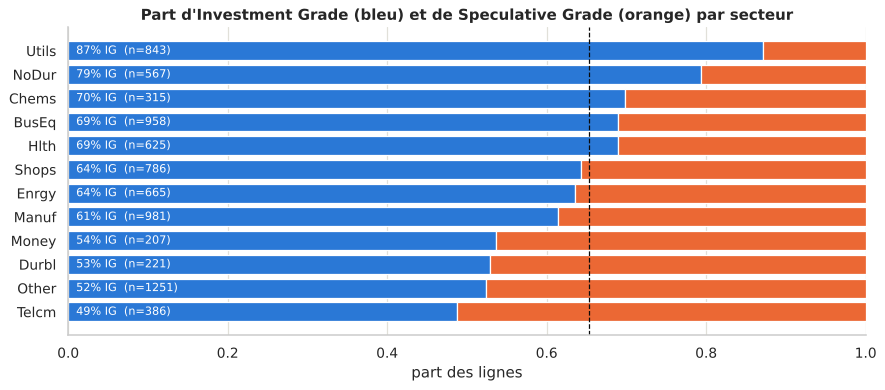

In [25]:
def cramers_v(x, y, corrige=True):
    # V de Cramér ; version corrigée du biais (Bergsma, 2013) : le V « naïf » grimpe
    # mécaniquement quand une variable a beaucoup de modalités.
    t = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(t, correction=False)[0]
    n = t.values.sum(); r, k = t.shape
    phi2 = chi2 / n
    if not corrige:
        return np.sqrt(phi2 / (min(r, k) - 1))
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / max(min(kc - 1, rc - 1), 1e-12))

df["SIC2"] = (df["SIC Code"] // 100).astype(int)      # division industrielle (2 premiers chiffres)

# Niveau entreprise : une ligne par CIK, label majoritaire (pour neutraliser les répétitions)
ent = df.groupby("CIK").agg(Sector=("Sector", "first"), SIC2=("SIC2", "first"),
                            SIC=("SIC Code", "first"), ig=("Binary Rating", "mean"))
ent["Cible"] = (ent["ig"] > .5).astype(int)

lignes_cat = []
for nom, col_df, col_ent in [("Sector", "Sector", "Sector"), ("Agence", "Agence", None),
                             ("SIC2 (2 chiffres)", "SIC2", "SIC2"), ("SIC Code (4 chiffres)", "SIC Code", "SIC")]:
    lignes_cat.append({"variable": nom, "modalités": df[col_df].nunique(),
                       "V naïf (lignes)": cramers_v(df[col_df], df["Binary Rating"], corrige=False),
                       "V corrigé (lignes)": cramers_v(df[col_df], df["Binary Rating"]),
                       "V corrigé (1 ligne par entreprise)": cramers_v(ent[col_ent], ent["Cible"]) if col_ent else np.nan})
cat = pd.DataFrame(lignes_cat).set_index("variable")
display(cat.round(3))
print("Entreprises par code SIC (4 chiffres) : médiane =", int(ent.groupby('SIC').size().median()))

sect = df.groupby("Sector")["Binary Rating"].agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(sect.index, sect["mean"], color=C_IG)
ax.barh(sect.index, 1 - sect["mean"], left=sect["mean"], color=C_SG)
for i, (m, n) in enumerate(zip(sect["mean"], sect["size"])):
    ax.text(0.01, i, f"{m:.0%} IG  (n={n})", va="center", color="white", fontsize=9)
ax.axvline(df["Binary Rating"].mean(), color="#0b0b0b", ls="--", lw=1)
ax.set(title="Part d'Investment Grade (bleu) et de Speculative Grade (orange) par secteur",
       xlim=(0, 1), xlabel="part des lignes")
plt.tight_layout(); plt.show()

### Interprétation

- **Le secteur compte** (V de Cramér ≈ 0,22-0,23, stable quelle que soit la méthode). Les *utilities* sont à 87 % IG (revenus régulés, très prévisibles), alors que les télécoms (49 %) et la catégorie « Other » (52 %) sont bien plus risqués. → `Sector` est une variable utile, à encoder en **one-hot** (12 modalités, c'est raisonnable).
- **L'agence compte aussi** (V = 0,21), ce qui confirme la section 5.2.
- **Le code SIC est un piège.** *(Le code SIC, Standard Industrial Classification, est le code d'activité officiel américain, à 4 chiffres. Les 2 premiers chiffres donnent la division industrielle.)* À 4 chiffres, son V « naïf » de 0,66 semble excellent, mais il vient surtout de sa **haute cardinalité** : 240 codes pour 686 entreprises, soit une **médiane de 2 entreprises par code**. Un code SIC identifie presque l'entreprise, donc il « mémorise » sa note. Au niveau entreprise et corrigé du biais, il retombe à 0,32. → Le SIC à 4 chiffres est **exclu** (risque de sur-apprentissage). Le même phénomène touche, en plus faible, le SIC à 2 chiffres : son V passe de 0,44 sur les lignes à 0,30 au niveau entreprise. Le SIC à 2 chiffres (62 divisions) pourra être testé avec un encodage régularisé (*target encoding* calculé dans les folds), en comparaison du simple secteur.

### Zoom : pourquoi le code SIC à 4 chiffres est un « identifiant déguisé »

**CIK et SIC : deux codes de la SEC, deux rôles différents.**

| | **CIK** (*Central Index Key*) | **SIC** (*Standard Industrial Classification*) |
|---|---|---|
| Répond à la question | **Qui** est l'entreprise ? | **Que fait** l'entreprise ? |
| Nature | numéro d'identité unique | code d'activité |
| Partagé entre entreprises ? | non : 1 CIK = 1 entreprise | oui : plusieurs entreprises peuvent avoir le même |
| Dans ce dataset | 686 CIK | 240 codes |
| Usage dans le projet | **groupes de split** (D1), jamais une variable explicative | variable explicative candidate |

**Le code SIC est hiérarchique** : plus on lit de chiffres, plus l'activité est précise. Par exemple, **49**xx = électricité, gaz et eau → **494**x = distribution d'eau → **4941** = distribution d'eau potable (American States Water, California Water Service…). De même, **73**xx = services aux entreprises → **7374** = traitement de données (ADP, Fiserv…).

Le risque : si un code ne contient qu'une ou deux entreprises, il désigne en pratique **une entreprise précise**, comme un CIK. Le modèle apprendrait alors « code 4941 → IG » par cœur, au lieu d'apprendre le lien entre ratios et risque. La cellule suivante le mesure.

In [26]:
# Combien d'entreprises partagent chaque code ? (table « ent » : une ligne par entreprise, section 7.2)
taille_code = pd.DataFrame({
    "nb codes": [ent["SIC"].nunique(), ent["SIC2"].nunique(), ent["Sector"].nunique()],
    "entreprises par code (médiane)": [ent.groupby(c).size().median() for c in ["SIC", "SIC2", "Sector"]],
    "codes ne contenant qu'1 entreprise": [(ent.groupby(c).size() == 1).sum() for c in ["SIC", "SIC2", "Sector"]],
}, index=["SIC 4 chiffres", "SIC 2 chiffres", "Secteur"])
display(taille_code)

# Démonstration : avec un split PAR ENTREPRISE (D1), combien d'entreprises du test ont un code jamais vu à l'entraînement ?
rng = np.random.default_rng(SEED)
res = []
for _ in range(20):                                   # 20 tirages pour stabiliser le résultat
    test_cik = rng.choice(ent.index, size=int(0.2 * len(ent)), replace=False)
    test, train = ent.loc[test_cik], ent.drop(test_cik)
    res.append({c: (~test[c].isin(train[c])).mean() for c in ["SIC", "SIC2", "Sector"]})
inconnus = pd.DataFrame(res).mean().rename("part des entreprises du test au code inconnu du train")
inconnus.index = ["SIC 4 chiffres", "SIC 2 chiffres", "Secteur"]
inconnus.to_frame().style.format("{:.0%}")

,nb codes,entreprises par code (médiane),codes ne contenant qu'1 entreprise
SIC 4 chiffres,240,2.0,108
SIC 2 chiffres,62,5.0,9
Secteur,12,48.5,0


,part des entreprises du test au code inconnu du train
SIC 4 chiffres,20%
SIC 2 chiffres,2%
Secteur,0%


### Interprétation : du plus précis au plus large

- **SIC à 4 chiffres : trop précis.** 240 codes pour 686 entreprises, médiane de **2 entreprises par code**, et **108 codes ne contiennent qu'une seule entreprise**. Pour ces entreprises, le code SIC est en pratique un **identifiant déguisé** : il dit *qui* est l'entreprise plutôt que *ce qu'elle fait*. C'est ce qui gonflait son V de Cramér (0,66 en apparence, 0,32 une fois la mémorisation neutralisée).
- **Il serait en plus inutilisable en test.** Avec un split par entreprise (décision D1), **environ 20 % des entreprises du test ont un code SIC à 4 chiffres qui n'apparaît jamais dans le train** (moyenne sur 20 tirages). Pour elles, le modèle n'aurait rien appris sur ce code.
- **SIC à 2 chiffres : intermédiaire.** 62 divisions, médiane de 5 entreprises par division, 9 divisions à une seule entreprise, 2 % de codes inconnus en test. La mémorisation est plus faible mais existe encore (V de 0,44 → 0,30) : on le **testera avec précaution** (*target encoding* calculé dans les folds), en comparaison du secteur.
- **Secteur : sûr.** 12 catégories, environ 49 entreprises par secteur, aucun code inconnu en test, et un V stable (≈ 0,22) quelle que soit la méthode. C'est lui qui porte l'information « métier » dans nos modèles.

**En résumé** : le CIK dit *qui* est l'entreprise (on l'utilise pour séparer train et test, jamais comme variable) ; le SIC dit *ce qu'elle fait*, mais à 4 chiffres il est si précis qu'il redevient un identifiant. On le remplace donc par le secteur.

# 8. Réduction de dimension et détection d'anomalies

**Choix de l'échantillon.** Les méthodes non supervisées sont appliquées aux **2 694 bilans distincts** et non aux 7 805 lignes : sinon un bilan noté 10 fois pèserait 10 fois plus dans la PCA ou le clustering. Chaque bilan reçoit le label majoritaire de ses notations (les ex aequo sont classés SG, par prudence).

**Transformation.** Les ratios sont passés par une transformation quantile vers une loi normale : c'est la variante qui neutralise le mieux les queues extrêmes (section 6.3), et la PCA comme KMeans reposent sur des distances euclidiennes, très sensibles aux échelles et aux valeurs extrêmes.

In [27]:
# Note médiane de chaque bilan (en crans), pour colorer les projections
bilans["notch"] = df.groupby("bilan_id")["notch"].median().values

X_unsup = QuantileTransformer(output_distribution="normal", n_quantiles=1000,
                              random_state=SEED).fit_transform(bilans[RATIOS])
X_unsup = StandardScaler().fit_transform(X_unsup)

## 8.1 Analyse en composantes principales (PCA)

**Le principe, en clair.** On a 16 ratios, donc chaque bilan est un point dans un espace à 16 dimensions, impossible à visualiser. La PCA cherche de **nouveaux axes**, appelés **composantes principales**, qui résument au mieux ces 16 ratios :
- la **PC1** est la direction selon laquelle les bilans sont le plus dispersés (celle qui « explique » le plus de variance) ;
- la **PC2** est la meilleure direction suivante, perpendiculaire à la première, et ainsi de suite.

Chaque composante est une **combinaison des ratios d'origine**. Les **loadings** indiquent le poids de chaque ratio dans une composante : un loading fort (positif ou négatif) signifie que ce ratio « pilote » la composante. C'est ce qui permet de leur donner un sens économique.

**Ce qu'on cherche à savoir** : (1) combien de dimensions « réelles » contiennent nos données ? (2) les axes principaux ont-ils un sens financier ? (3) les IG et les SG se séparent-ils dans ce nouvel espace ?

2 composantes : 54.8% de la variance
3 composantes : 65.6% de la variance
5 composantes : 81.0% de la variance
Composantes nécessaires pour 90 % : 8


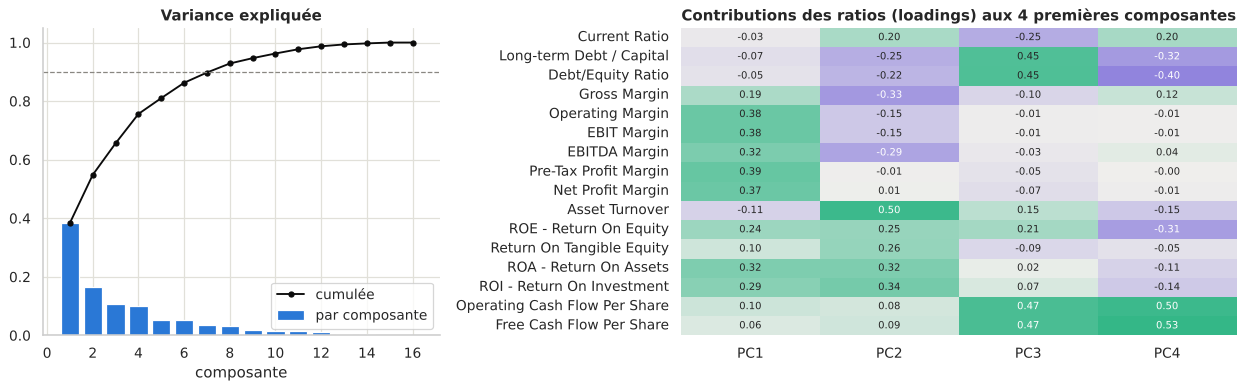

In [28]:
pca = PCA(random_state=SEED).fit(X_unsup)
var = pca.explained_variance_ratio_
cum = np.cumsum(var)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].bar(range(1, 17), var, color=C_IG, label="par composante")
axes[0].plot(range(1, 17), cum, color="#0b0b0b", marker="o", ms=4, lw=1.5, label="cumulée")
axes[0].axhline(0.9, color=C_NEUTRE, ls="--", lw=1)
axes[0].set(title="Variance expliquée", xlabel="composante", ylim=(0, 1.05)); axes[0].legend()

load = pd.DataFrame(pca.components_[:4].T, index=RATIOS, columns=[f"PC{i}" for i in range(1, 5)])
sns.heatmap(load, cmap=CMAP_DIV, center=0, vmin=-.6, vmax=.6, annot=True, fmt=".2f",
            annot_kws={"size": 8}, ax=axes[1], cbar=False)
axes[1].set_title("Contributions des ratios (loadings) aux 4 premières composantes")
plt.tight_layout(); plt.show()

for k in (2, 3, 5):
    print(f"{k} composantes : {cum[k-1]:.1%} de la variance")
print(f"Composantes nécessaires pour 90 % : {np.argmax(cum >= .9) + 1}")

Corrélation de Spearman entre PC1 et la note (en crans) : -0.448
Corrélation de Spearman entre PC2 et la note (en crans) : -0.17


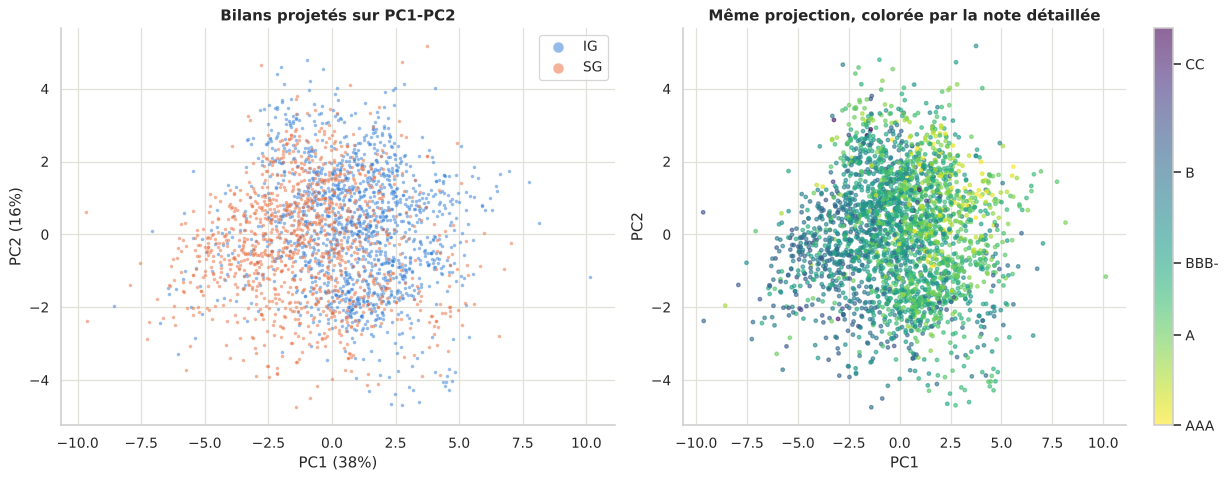

In [29]:
Z = pca.transform(X_unsup)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for cible in ["IG", "SG"]:
    m = bilans["Cible"] == cible
    axes[0].scatter(Z[m, 0], Z[m, 1], s=8, alpha=.5, color=PAL_CIBLE[cible], label=cible,
                    edgecolors="white", linewidths=0.2)
axes[0].set(title="Bilans projetés sur PC1-PC2", xlabel=f"PC1 ({var[0]:.0%})", ylabel=f"PC2 ({var[1]:.0%})")
axes[0].legend(markerscale=3)

sc = axes[1].scatter(Z[:, 0], Z[:, 1], s=8, c=bilans["notch"], cmap="viridis_r", alpha=.6)
axes[1].set(title="Même projection, colorée par la note détaillée", xlabel="PC1", ylabel="PC2")
cb = plt.colorbar(sc, ax=axes[1]); cb.set_ticks([0, 5, 9, 14, 20]); cb.set_ticklabels(["AAA", "A", "BBB-", "B", "CC"])
plt.tight_layout(); plt.show()

print("Corrélation de Spearman entre PC1 et la note (en crans) :",
      round(stats.spearmanr(Z[:, 0], bilans["notch"])[0], 3))
print("Corrélation de Spearman entre PC2 et la note (en crans) :",
      round(stats.spearmanr(Z[:, 1], bilans["notch"])[0], 3))

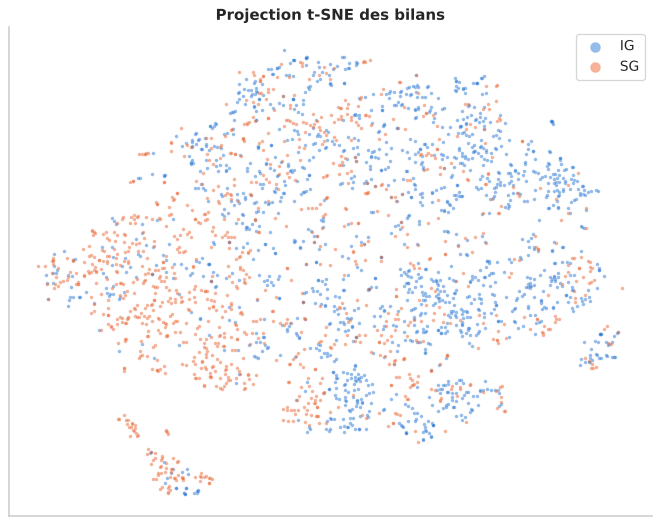

In [30]:
# t-SNE : projection NON LINÉAIRE en 2D. Contrairement à la PCA, elle cherche à garder ensemble
# les points proches dans l'espace d'origine, ce qui peut révéler des groupes que la PCA écrase.
# Attention : les distances ENTRE groupes et la taille des groupes n'y ont pas de sens ; seuls les
# voisinages locaux sont interprétables. C'est un outil de visualisation, pas une mesure.
tsne = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED)
T = tsne.fit_transform(X_unsup)
fig, ax = plt.subplots(figsize=(7.5, 6))
for cible in ["IG", "SG"]:
    m = bilans["Cible"] == cible
    ax.scatter(T[m, 0], T[m, 1], s=8, alpha=.5, color=PAL_CIBLE[cible], label=cible, edgecolors="white", linewidths=0.2)
ax.set(title="Projection t-SNE des bilans", xticks=[], yticks=[]); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

### Interprétation

- **Pas de dimension dominante** : PC1 explique 38 % de la variance, PC2 16 %. Il faut **8 composantes pour 90 %**, sur 16 ratios. La redondance est réelle (les marges), mais l'information reste répartie sur plusieurs axes.
- **Lecture des axes** (loadings) :
  - **PC1 = rentabilité** : toutes les marges, ROA, ROI et ROE y contribuent positivement ;
  - **PC2 = modèle économique** : rotation des actifs et rendements élevés, contre marges brutes et EBITDA élevés et endettement (distributeurs « légers » contre industries lourdes en capital) ;
  - **PC3 = endettement et cash-flows** ;
  - **PC4 = cash-flows par action contre endettement et ROE**.
- **Lien avec le risque** : PC1 est clairement corrélée à la note (Spearman −0,45, une note plus élevée en crans signifiant plus risquée). Les SG se concentrent à gauche (faible rentabilité), avec un **fort recouvrement** au centre. PC2 n'est presque pas liée au risque (−0,17).
- **t-SNE** : on n'observe aucun groupe nettement séparé, mais des **zones à dominante IG ou SG** (les SG plutôt à gauche) et de petits îlots homogènes, qui correspondent probablement à des secteurs ou à des entreprises notées plusieurs années de suite avec des bilans proches.
- **Réserve** : la PCA et le t-SNE sont ajustés ici sur toutes les données, ce qui est normal pour une exploration. Si la PCA est utilisée comme étape d'un pipeline (piste ci-dessous), elle sera ajustée **sur le train uniquement**.
- **Conclusion** : les classes ne sont **pas linéairement séparables** dans l'espace des ratios. Un modèle linéaire capturera la tendance principale (la rentabilité), mais les modèles non linéaires (arbres, boosting, SVM à noyau) devraient mieux gérer le recouvrement. La PCA sera testée comme **étape de réduction de dimension** dans un pipeline, en comparaison des variables brutes.

## 8.2 Détection d'anomalies (Isolation Forest)

**Le principe, en clair.** L'Isolation Forest coupe les données au hasard, encore et encore (« ROA < 3 ? », puis « Debt/Equity > 1,2 ? »…), jusqu'à isoler chaque point. Un bilan **atypique** est isolé en **très peu de coupes**, parce qu'il est seul dans sa zone. Un bilan « normal », noyé parmi ses semblables, en demande beaucoup. En répétant l'opération sur 300 arbres, on obtient un **score d'anomalie** pour chaque bilan.

Le paramètre `contamination = 5 %` fixe la part de bilans qu'on décide d'appeler « anomalies ». C'est un **choix arbitraire** : il sert ici à examiner les cas les plus atypiques, pas à les supprimer.

**Ce qu'on cherche à savoir** : qui sont ces bilans atypiques ? Sont-ils plus risqués ? Faut-il les retirer ?

Bilans signalés comme anomalies : 135 (5%)
Part de SG parmi les anomalies : 60.0% (contre 42.1% parmi les autres)
Secteurs surreprésentés parmi les anomalies : {'Enrgy': 0.17, 'Other': 0.11, 'Hlth': 0.03}


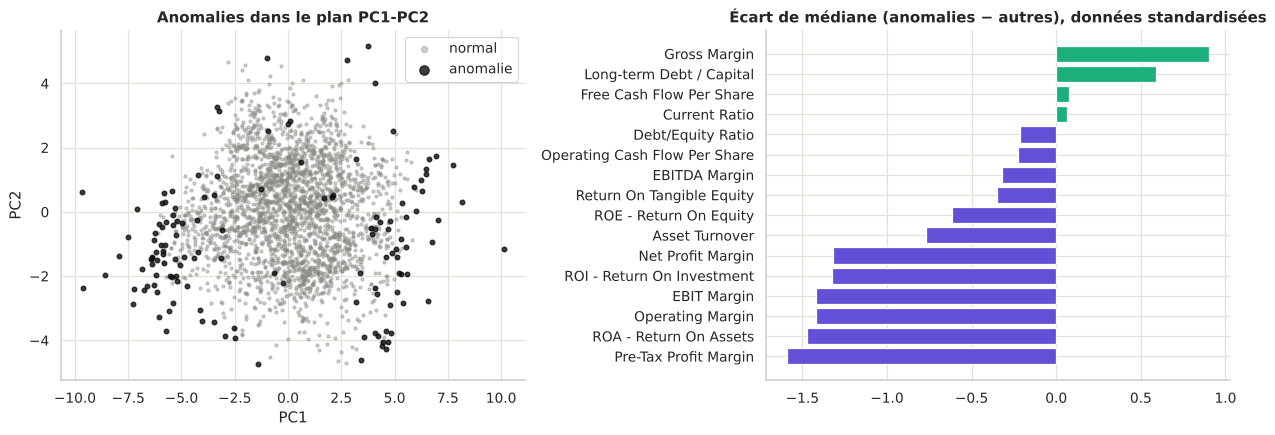

In [31]:
iso = IsolationForest(n_estimators=300, contamination=0.05, random_state=SEED)
bilans["anomalie"] = iso.fit_predict(X_unsup) == -1
print(f"Bilans signalés comme anomalies : {bilans['anomalie'].sum()} ({bilans['anomalie'].mean():.0%})")
print(f"Part de SG parmi les anomalies : {(bilans.loc[bilans.anomalie, 'Cible'] == 'SG').mean():.1%} "
      f"(contre {(bilans.loc[~bilans.anomalie, 'Cible'] == 'SG').mean():.1%} parmi les autres)")

# Qu'est-ce qui rend ces bilans atypiques ? Écart des médianes (en données transformées)
Xd = pd.DataFrame(X_unsup, columns=RATIOS)
ecart = (Xd[bilans.anomalie.values].median() - Xd[~bilans.anomalie.values].median()).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for flag, col, lab in [(False, C_NEUTRE, "normal"), (True, "#0b0b0b", "anomalie")]:
    m = bilans["anomalie"] == flag
    axes[0].scatter(Z[m, 0], Z[m, 1], s=6 if not flag else 14, alpha=.4 if not flag else .8, color=col, label=lab)
axes[0].set(title="Anomalies dans le plan PC1-PC2", xlabel="PC1", ylabel="PC2"); axes[0].legend(markerscale=2)
axes[1].barh(ecart.index, ecart.values, color=["#6250d6" if v < 0 else "#1baf7a" for v in ecart.values])
axes[1].set(title="Écart de médiane (anomalies − autres), données standardisées")
plt.tight_layout(); plt.show()
print("Secteurs surreprésentés parmi les anomalies :",
      (bilans.loc[bilans.anomalie, "Sector"].value_counts(normalize=True)
       - bilans["Sector"].value_counts(normalize=True)).sort_values(ascending=False).head(3).round(2).to_dict())

### Interprétation

- L'Isolation Forest isole 135 bilans (5 %, taux fixé par hypothèse). Ce sont des bilans **plus risqués que la moyenne** : **60 % des anomalies sont SG, contre 42 % des autres bilans** : marges et rendements nettement inférieurs à la normale, endettement élevé, mais marge brute haute. Ce profil est typique d'entreprises à **coûts fixes lourds en perte**.
- Le secteur de l'énergie y est surreprésenté (+17 points), ce qui est cohérent avec la crise pétrolière de 2014-2016 vue en section 5.3.
- Dans le plan PCA, les anomalies sont aux **deux extrémités de PC1** : entreprises en grande difficulté d'un côté, rentabilités exceptionnelles de l'autre.
- **Décision** : ces bilans **ne sont pas supprimés**. Ce sont des cas réels et souvent informatifs pour la classe SG. On pourra tester le **score d'anomalie comme feature** (calculé sur le train uniquement), ou un pipeline qui les retire du train seulement, pour mesurer leur impact.

# 9. Clustering non supervisé

Question posée : **si on regroupe les entreprises uniquement d'après leurs ratios, sans connaître leur note, les groupes obtenus correspondent-ils au risque de crédit ?**

On compare deux algorithmes :
- **KMeans** : on choisit un nombre de groupes *k* ; l'algorithme place *k* centres, range chaque bilan dans le groupe du centre le plus proche, puis déplace les centres jusqu'à stabilisation. Les groupes obtenus sont « ronds ».
- **Mélange gaussien (GMM)** : chaque groupe est modélisé par une loi normale, qui peut être allongée ou inclinée. C'est plus souple que KMeans.

Comme pour la PCA, on travaille sur les **bilans distincts** et les ratios **transformés** (section 8).

## 9.1 Choix du nombre de clusters

Il n'y a pas de « bonne réponse » évidente pour *k*. On regarde trois critères :
- **l'inertie** (KMeans) : la distance totale des bilans à leur centre. Elle baisse toujours quand *k* augmente ; on cherche un **coude**, à partir duquel ajouter un groupe n'apporte plus grand-chose ;
- **la silhouette** (KMeans) : pour chaque bilan, est-il plus proche de son propre groupe que du groupe voisin ? Elle va de −1 à 1 ; **plus elle est haute, plus les groupes sont nets** (au-delà de 0,5 : groupes bien séparés ; sous 0,25 : structure faible) ;
- **le BIC** (GMM) : un compromis entre la qualité d'ajustement et la complexité du modèle ; **plus il est bas, mieux c'est**.

k,2,3,4,5,6,7,8,9,10
silhouette KMeans,0.212,0.162,0.155,0.134,0.138,0.142,0.146,0.138,0.134
BIC GMM,42308.305,35119.552,35032.495,33245.554,30789.922,30067.377,27894.826,28958.418,28805.711


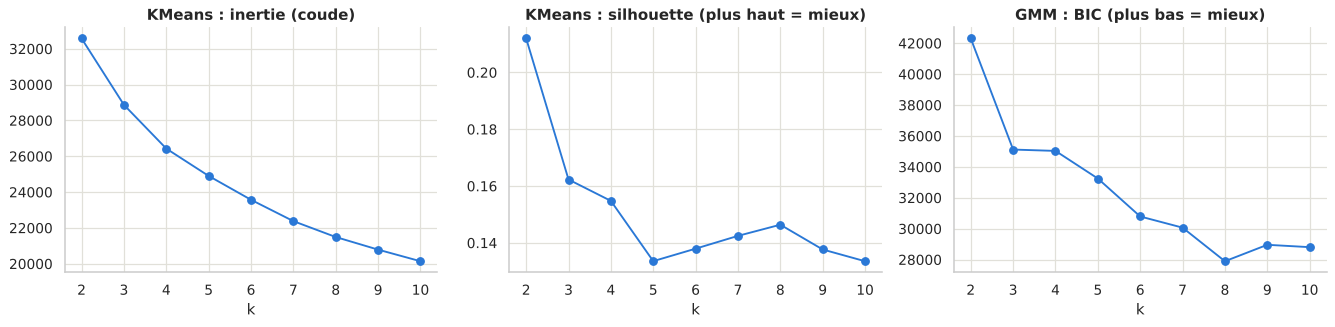

In [32]:
ks = range(2, 11)
inertie, silh, bic = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_unsup)
    inertie.append(km.inertia_)
    silh.append(silhouette_score(X_unsup, km.labels_, sample_size=2000, random_state=SEED))
    gm = GaussianMixture(n_components=k, covariance_type="full", random_state=SEED).fit(X_unsup)
    bic.append(gm.bic(X_unsup))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(ks, inertie, marker="o", color=C_IG); axes[0].set(title="KMeans : inertie (coude)", xlabel="k")
axes[1].plot(ks, silh, marker="o", color=C_IG); axes[1].set(title="KMeans : silhouette (plus haut = mieux)", xlabel="k")
axes[2].plot(ks, bic, marker="o", color=C_IG); axes[2].set(title="GMM : BIC (plus bas = mieux)", xlabel="k")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(ks), "silhouette KMeans": silh, "BIC GMM": bic}).set_index("k").round(3).T

### Interprétation

- La **silhouette** est maximale pour k = 2 (0,21) puis décroît, mais **reste faible partout** (< 0,25). Il n'existe pas de groupes naturellement bien séparés dans les données.
- Le **BIC** du modèle de mélange gaussien baisse jusqu'à k ≈ 8. Il préfère beaucoup de composantes : signe que les données forment un **nuage continu**, que le GMM approxime par morceaux, plutôt que des groupes distincts.
- L'inertie ne montre **pas de coude net** : elle décroît régulièrement.
- Aucun critère ne s'impose clairement. On compare donc plusieurs *k* à la cible ci-dessous.
- **Pourquoi retenir k = 4 alors que la silhouette préfère k = 2 ?** Avec k = 2, KMeans coupe simplement le nuage en deux le long de la rentabilité (PC1) : on n'apprend rien de plus que la PCA. Avec k = 4, la silhouette baisse peu (0,21 → 0,16) mais on obtient des **profils économiques interprétables** (section 9.2). Comme aucune valeur de *k* ne donne de groupes nets, on privilégie celle qui apporte le plus de compréhension.

### Les groupes trouvés correspondent-ils à la cible ?

On compare les groupes à la classe IG / SG avec trois indicateurs :
- **ARI** (*Adjusted Rand Index*) : les paires de bilans rangées ensemble par le clustering sont-elles aussi de la même classe ? 0 = pas mieux que le hasard, 1 = correspondance parfaite ;
- **NMI** (*Normalized Mutual Information*) : à quel point connaître le groupe renseigne sur la classe, de 0 à 1 ;
- **pureté** : si on attribue à chaque groupe sa classe majoritaire, quelle part des bilans serait bien classée ? À comparer à 57 %, la part de la classe majoritaire (IG) chez les bilans.

In [33]:
# Comparaison des partitions à la cible, pour plusieurs k
comp = []
for k in [2, 3, 4, 5, 6]:
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_unsup)
    comp.append({"k": k,
                 "ARI vs IG/SG": adjusted_rand_score(bilans["Cible"], lab),
                 "NMI vs IG/SG": normalized_mutual_info_score(bilans["Cible"], lab),
                 "NMI vs niveau de risque (5 classes)": normalized_mutual_info_score(
                     pd.cut(bilans["notch"], [-1, 3, 6, 9, 12, 30]), lab),
                 "pureté IG/SG": pd.crosstab(lab, bilans["Cible"]).max(axis=1).sum() / len(lab)})
pd.DataFrame(comp).set_index("k").round(3)

,ARI vs IG/SG,NMI vs IG/SG,NMI vs niveau de risque (5 classes),pureté IG/SG
k,,,,
2,0.126,0.088,0.072,0.678
3,0.087,0.078,0.068,0.689
4,0.055,0.064,0.066,0.676
5,0.045,0.062,0.068,0.664
6,0.039,0.055,0.062,0.662


## 9.2 Profil des clusters

,bilans,part_IG,note_médiane,secteurs_dominants
cluster,,,,
0,541,0.769,BBB+,"BusEq 22%, Other 20%, Hlth 15%"
1,808,0.623,BBB,"Manuf 21%, Shops 21%, Other 14%"
2,758,0.619,BBB,"Utils 26%, Other 14%, Telcm 10%"
3,587,0.250,BB-,"Other 21%, Manuf 17%, Shops 14%"


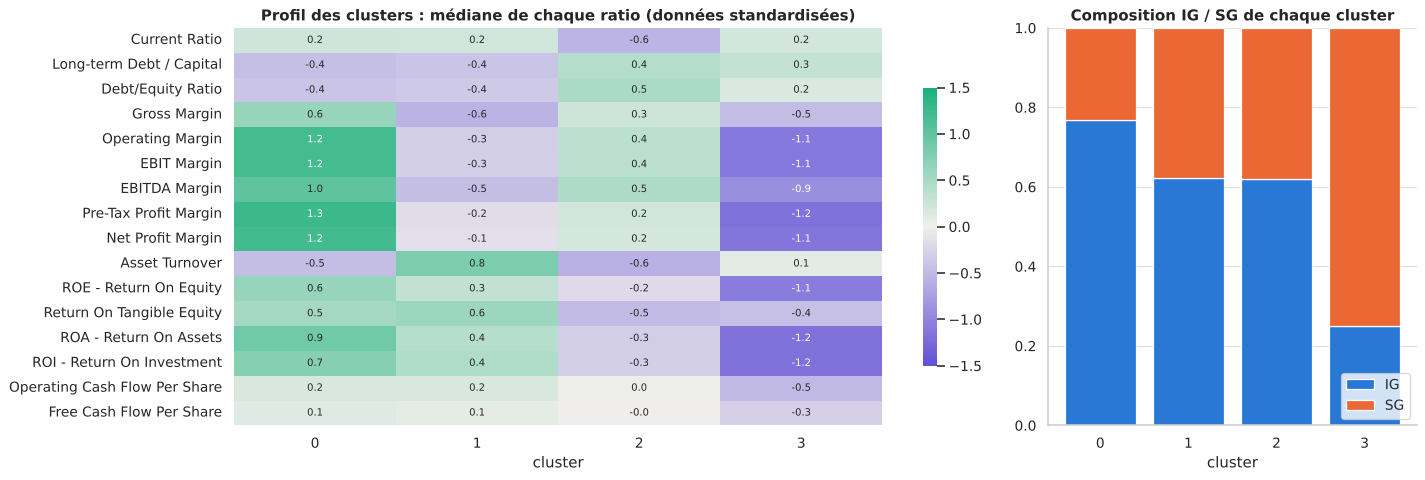

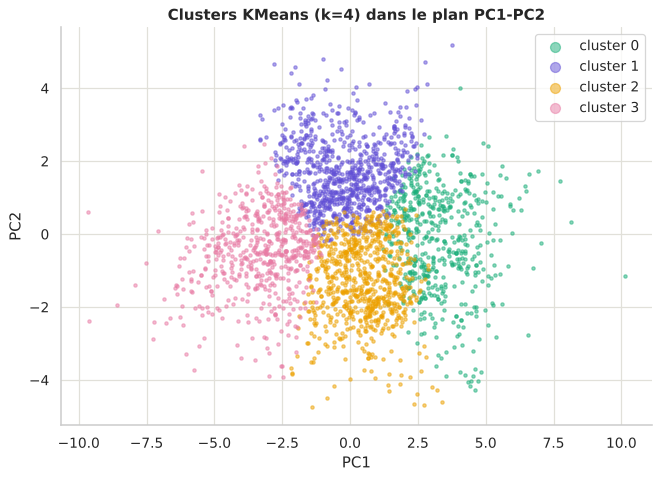

In [34]:
K = 4
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X_unsup)
bilans["cluster"] = km.labels_

# On renumérote les clusters du plus « sûr » au plus « risqué » pour faciliter la lecture
ordre_cl = bilans.groupby("cluster")["part_IG"].mean().sort_values(ascending=False).index
bilans["cluster"] = bilans["cluster"].map({c: i for i, c in enumerate(ordre_cl)})

profil = bilans.groupby("cluster").agg(bilans=("Cible", "size"),
                                       part_IG=("Cible", lambda s: (s == "IG").mean()),
                                       note_médiane=("notch", lambda s: RATING_ORDER[int(round(s.median()))]),
                                       secteurs_dominants=("Sector", lambda s: ", ".join(
                                           f"{k} {v:.0%}" for k, v in s.value_counts(normalize=True).head(3).items())))
display(profil.round(3))

med = pd.DataFrame(X_unsup, columns=RATIOS).groupby(bilans["cluster"].values).median()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [2.2, 1]})
sns.heatmap(med.T, cmap=CMAP_DIV, center=0, vmin=-1.5, vmax=1.5, annot=True, fmt=".1f",
            annot_kws={"size": 8}, ax=axes[0], cbar_kws={"shrink": .7})
axes[0].set(title="Profil des clusters : médiane de chaque ratio (données standardisées)", xlabel="cluster")
ct = pd.crosstab(bilans["cluster"], bilans["Cible"], normalize="index")
axes[1].bar(ct.index, ct["IG"], color=C_IG, label="IG")
axes[1].bar(ct.index, ct["SG"], bottom=ct["IG"], color=C_SG, label="SG")
axes[1].set(title="Composition IG / SG de chaque cluster", xlabel="cluster", ylim=(0, 1), xticks=range(K))
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 5.5))
pal_cl = ["#1baf7a", "#6250d6", "#eda100", "#e87ba4", "#0b0b0b", "#898781"]   # distinctes du bleu / orange réservés à IG / SG
for c in range(K):
    m = bilans["cluster"] == c
    ax.scatter(Z[m, 0], Z[m, 1], s=7, alpha=.5, color=pal_cl[c], label=f"cluster {c}")
ax.set(title=f"Clusters KMeans (k={K}) dans le plan PC1-PC2", xlabel="PC1", ylabel="PC2"); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

### Interprétation : les clusters capturent des modèles économiques plus que le risque

- **Accord faible avec la cible** (tableau précédent) : l'ARI vaut au mieux 0,13 (k = 2) et la NMI reste sous 0,09. La pureté IG / SG (68 %) dépasse à peine la part de la classe majoritaire chez les bilans (57 %). Le clustering **ne retrouve pas** la séparation IG / SG à lui seul.
- Avec **k = 4**, retenu pour sa lisibilité, on obtient pourtant des profils économiques clairs :
  - **Cluster 0 : entreprises très rentables** (marges et rendements élevés, peu de dette). 77 % IG ; technologie, santé.
  - **Cluster 1 : modèle « volume »** (forte rotation des actifs, marge brute faible). 62 % IG ; industrie, distribution.
  - **Cluster 2 : modèle « capital lourd »** (endettement élevé, faible liquidité, faible rotation). 62 % IG ; *utilities*, télécoms.
  - **Cluster 3 : entreprises peu ou pas rentables** (toutes les marges et rendements très inférieurs à la normale). **Seulement 25 % IG**, note médiane BB-.
- **Lecture** : seul le cluster 3 est vraiment associé au risque. Les clusters 1 et 2 ont la même part d'IG mais des ratios très différents : **un même niveau d'endettement ou de marge ne signifie pas le même risque selon le modèle économique**. Une *utility* très endettée peut être IG grâce à ses revenus régulés, alors qu'une entreprise de distribution au même niveau de dette ne le serait pas.
- **Conséquences pour la modélisation** :
  - il faut des modèles capables de capter des **interactions** (arbres, boosting) ;
  - il faut aussi des features **relatives au secteur** (ratio − médiane du secteur, calculée sur le train) ;
  - l'appartenance à un cluster, ou la distance aux centres (KMeans ajusté sur le train), pourra être testée comme **feature supplémentaire**.

# 10. Conclusions de l'exploration et décisions pour la modélisation

## Ce que nous avons appris

1. **Données propres mais très répétitives.** Il n'y a aucune valeur manquante ni ligne dupliquée, mais seulement 2 694 bilans distincts pour 7 805 lignes : 89 % des lignes ont un jumeau, et 686 entreprises réelles se cachent derrière 1 377 noms. Les doublons surreprésentent les IG (65 % sur les lignes, 57 % sur les bilans).
2. **Cible modérément déséquilibrée** (65 % IG / 35 % SG) et **partiellement bruitée** : les agences ne sont pas d'accord dans 12 % des cas où elles notent le même bilan, et Egan-Jones est systématiquement plus généreuse (résultat cohérent avec la littérature). Un score parfait est impossible.
3. **Ratios à queues extrêmes, mais informatives** : les lignes extrêmes sont plus souvent SG (51 % contre 35 %). Les fonds propres négatifs sont un signal fort, mais mal ordonné numériquement.
4. **La rentabilité est le premier facteur de risque** (marges nettes, ROA, ROI : AUC univariée de 0,71 à 0,75), suivie de l'endettement. Les cash-flows par action ne discriminent presque pas.
5. **Forte redondance** dans la famille des marges (Operating ≈ EBIT, ρ = 0,999).
6. **Le secteur et le modèle économique comptent** : le même ratio n'a pas le même sens selon l'activité (clusters 1 et 2 ; Current Ratio plus bas chez les IG dans certains secteurs seulement). Le code SIC détaillé est un piège de sur-apprentissage.
7. **Pas de structure naturelle séparant IG et SG** : les classes se recouvrent fortement, ce qui favorise les modèles non linéaires.
8. **Les doublons faussent toute méthode fondée sur la proximité** : l'information mutuelle calculée sur les lignes brutes est uniforme et gonflée.

## Décisions pour la suite

| # | Décision | Justification |
|---|---|---|
| D1 | Tous les splits et folds de CV **par CIK** (`StratifiedGroupKFold`) | 89 % des lignes ont un jumeau : risque majeur de data leakage |
| D2 | Garder toutes les lignes, **agence en variable** ; pipeline de comparaison sans agence | biais d'agence systématique et mesurable |
| D3 | Métriques : **ROC-AUC, PR-AUC, rappel SG**, F1, balanced accuracy | déséquilibre de classes et coût asymétrique des erreurs |
| D4 | **Garder les extrêmes**, les traiter dans le pipeline (winsorisation ou quantile, ajustés sur le train) | les extrêmes sont informatifs pour la classe SG |
| D5 | One-hot pour Sector et Agence ; **SIC à 4 chiffres exclu** ; version réduite des ratios à tester pour les modèles linéaires | redondance des marges ; SIC = identifiant déguisé |
| D6 | **PCA testée comme étape de pipeline** ; **anomalies gardées** (score d'anomalie comme variable possible) | information répartie sur 8 axes ; anomalies plus souvent SG |
| — | Exclure Corporation, Ticker, CIK et la date brute des features | identifiants ou variables à risque de mémorisation |

## Pistes de feature engineering (à tester)

- Indicateurs de signe : fonds propres négatifs, résultat négatif, ROE négatif ; indicateur « marge brute = 100 % ».
- Suppression d'une des deux marges quasi identiques (Operating / EBIT).
- Ratios relatifs au secteur (ratio − médiane du secteur, sur le train).
- Écarts entre marges (Gross − Operating : poids des charges d'exploitation).
- Score d'anomalie (Isolation Forest) et appartenance à un cluster (KMeans), ajustés sur le train.
- Indicateur « ROE négatif » / « résultat négatif » (révélé par le log signé, section 6.3).
- Année de notation.

## Hypothèses à vérifier en modélisation

- Le split par CIK donnera des scores **nettement inférieurs** à un split aléatoire : on chiffrera l'écart.
- Les modèles à arbres et le boosting surpasseront les modèles linéaires régularisés, grâce aux interactions et à leur insensibilité aux queues.
- Ajouter l'agence améliorera les scores, surtout autour de la frontière BBB- / BB+.
- Les performances baisseront sur 2015-2016 (crise du secteur de l'énergie) avec un split temporel.